# BVOC emissions: background change versus forest expansion (FUT)

Single notebook for **CTRL_PD, CTRL_FUT and LCC_FUT**, 2001–2009, monthly SFISOP/SFMTERP. It merges and replaces the earlier `bvoc_emissions_decomposition`, `bvoc_emissions_three_regions` and `bvoc_emissions_followup_investigation` notebooks.

**Background = CTRL_FUT − CTRL_PD**  
**Expansion = LCC_FUT − CTRL_FUT**  
**Total = LCC_FUT − CTRL_PD = Background + Expansion**

This is an exact emissions decomposition, not a decomposition of cloud/radiative responses. Values are mass of the emitted compound, not carbon mass.

| Region | Question |
|---|---|
| Modified cells within ≥45°N | What happens within the imposed vegetation-change footprint? |
| Unmodified cells ≥45°N | What happens outside that footprint? |
| All cells ≥45°N | What is the combined northern budget? |

For an exact partition, **modified cells are intersected with the northern domain**. Any modified cells south of the threshold are counted and reported, but excluded. The first two regions are disjoint; their emission totals sum to the third.

The expansion contrast includes vegetation-induced environmental responses, even within modified cells. It does not isolate a direct PFT emission-capacity effect. Background includes all environmental differences between the controls.

Sections 1–9 are the baseline decomposition; section 10 holds the conclusions drawn from it; sections 11–17 are the follow-up diagnostics (hotspots, mechanisms, fixed-emission checks, atmospheric responses). Optional inputs are switched off until their paths are set.

The PD-vs-FUT dependence of the expansion effect is in the separate notebook `bvoc_expansion_PD_FUT_interaction.ipynb`.

In [1]:
from pathlib import Path
from glob import glob
import calendar
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from IPython.display import display

FILES = {
    "CTRL_PD": "/cluster/home/adelez/BRL-FRST-XPSN_archive/NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925/atm/hist/*.cam.h0.*.nc",
    "CTRL_FUT": "/cluster/home/adelez/BRL-FRST-XPSN_archive/NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20260925/atm/hist/*.cam.h0.*.nc",
    "LCC_FUT": "/cluster/home/adelez/BRL-FRST-XPSN_archive/NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261005/atm/hist/*.cam.h0.*.nc",
}
START_YEAR, END_YEAR = 2001, 2009
MIN_LAT = 45
VARS = ["SFISOP", "SFMTERP"]
LABELS = {"SFISOP": "Isoprene", "SFMTERP": "Monoterpenes"}
COLORS = {"Background": "#4477AA", "Expansion": "#228833", "Total": "#333333"}
OUT = Path("bvoc_emissions_decomposition_outputs")
OUT.mkdir(exist_ok=True)

# Set True only for processed files whose timestamps identify the represented month.
# Raw CAM next-month timestamps require time bounds.
TRUST_TIMESTAMPS_WITHOUT_BOUNDS = False
AREA_FILE = None  # Optional NetCDF with cell area on the same lat/lon grid.
AREA_VAR, AREA_UNITS = "area", "m2"  # Alternatives: km2, sr
EARTH_RADIUS = 6_371_000
MASK_FILE = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/check-simulation-equilibrium/lcc-modified-cells/modified_cells.nc")
MASK_VAR = None  # e.g. "modified_cells"; auto-detect only a unique binary 2D candidate.
MASK_NAN_IS_FALSE = False  # Set True only if missing values explicitly mean unmodified.

RUN_MAPS = True  # Cartopy maps (needs the pyenv-cartopy / lcc-env kernel with coastline data).


## 1. Read monthly emissions once
Uses time bounds to identify complete calendar months and retains only SFISOP/SFMTERP. Re-running later plotting cells does not reload simulation files.

In [2]:
def seconds_between(start, end):
    delta = end - start
    return float(delta / np.timedelta64(1, "s")) if isinstance(delta, np.timedelta64) else delta.total_seconds()

def date_parts(value):
    if isinstance(value, np.datetime64):
        value = pd.Timestamp(value)
    return value.year, value.month, value.day, value.hour, value.minute, value.second

def read_case(pattern):
    paths = sorted(glob(str(Path(pattern).expanduser())))
    if not paths:
        raise FileNotFoundError(pattern)
    chunks, records = [], []
    for path in paths:
        with xr.open_dataset(path) as ds:
            bounds_name = ds.time.attrs.get("bounds")
            if not bounds_name or bounds_name not in ds:
                bounds_name = next((v for v in ("time_bnds", "time_bounds") if v in ds), None)
            selected, keys, durations = [], [], []
            for i, stamp in enumerate(ds.time.values):
                if bounds_name:
                    start, end = ds[bounds_name].isel(time=i).values.ravel()
                    midpoint = start + (end - start) / 2
                    year, month, *_ = date_parts(midpoint)
                    duration = seconds_between(start, end)
                    sy, sm, sd, sh, smin, ss = date_parts(start)
                    ey, em, ed, eh, emin, es = date_parts(end)
                    next_month = (sy + (sm == 12), sm % 12 + 1)
                    monthly = (sd == ed == 1 and (ey, em) == next_month
                               and (sy, sm) == (year, month) and 27 <= duration / 86400 <= 31
                               and sh == smin == ss == eh == emin == es == 0)
                else:
                    if not TRUST_TIMESTAMPS_WITHOUT_BOUNDS:
                        raise ValueError(f"{path}: no time bounds; confirm timestamp convention in configuration.")
                    year, month, *_ = date_parts(stamp)
                    duration = float(ds.time.dt.days_in_month.isel(time=i)) * 86400
                    monthly = True
                if not START_YEAR <= year <= END_YEAR:
                    continue
                if not monthly:
                    raise ValueError(f"{path}: record {i} is not a complete calendar month.")
                selected.append(i)
                keys.append(year * 100 + month)
                durations.append(duration)
            if not selected:
                continue
            for var in VARS:
                if set(ds[var].dims) != {"time", "lat", "lon"}:
                    raise ValueError(f"{path}: unexpected dimensions for {var}: {ds[var].dims}")
                unit = ds[var].attrs.get("units", "").lower().replace(" ", "").replace("**", "^")
                if unit not in {"kg/m2/s", "kg/m^2/s", "kgm-2s-1", "kgm^-2s^-1"}:
                    raise ValueError(f"{path}: verify units for {var}: {ds[var].attrs.get('units')}")
            chunk = ds[VARS].isel(time=selected).assign_coords(time=keys).load()
            chunk["seconds"] = ("time", durations)
            chunks.append(chunk)
            records.extend(keys)
    expected = [y * 100 + m for y in range(START_YEAR, END_YEAR + 1) for m in range(1, 13)]
    if sorted(records) != expected:
        raise ValueError("Expected exactly one record per month; check gaps, duplicates and selected years.")
    result = xr.concat(chunks, dim="time", join="exact").sortby("time").sortby("lat").sortby("lon")
    result = result.assign_coords(year=("time", result.time.values // 100),
                                  month=("time", result.time.values % 100))
    if not bool(np.isfinite(result[VARS].to_array()).all()):
        raise ValueError("Missing/nonfinite emissions: inspect before spatial integration.")
    print(f"{len(paths)} files inspected; {result.sizes['time']} monthly records loaded.")
    return result

cases = {alias: read_case(pattern) for alias, pattern in FILES.items()}
cases = dict(zip(cases, xr.align(*cases.values(), join="exact")))
reference = cases["CTRL_PD"]
for alias, ds in cases.items():
    np.testing.assert_allclose(ds.seconds, reference.seconds, rtol=0, atol=0)

120 files inspected; 108 monthly records loaded.
120 files inspected; 108 monthly records loaded.
120 files inspected; 108 monthly records loaded.


## 2. Cell area
Fluxes are grid-box-area fluxes in kg m⁻² s⁻¹. Integrate over whole grid-cell area; do not multiply by land fraction or changed-PFT fraction again. A modified grid cell may contain both changed and unchanged vegetation.

The default area estimate applies only to a regular global latitude–longitude grid. A supplied model area field is preferable when available.

In [3]:
def grid_area(ds):
    lat, lon = ds.lat.values, ds.lon.values
    if len(lat) < 2 or len(lon) < 2:
        raise ValueError("Need a full grid or an explicit area file.")
    dlat, dlon = np.diff(lat), np.diff(lon)
    if not (np.allclose(dlat, dlat[0]) and np.allclose(dlon, dlon[0])):
        raise ValueError("Nonuniform grid: provide AREA_FILE.")
    if not np.isclose(dlon[0] * len(lon), 360):
        raise ValueError("Expected global longitude coverage; provide AREA_FILE.")
    if lat[0] - dlat[0] / 2 > -89.99 or lat[-1] + dlat[0] / 2 < 89.99:
        raise ValueError("Expected global latitude coverage; provide AREA_FILE.")
    edges = np.r_[-90, (lat[:-1] + lat[1:]) / 2, 90]
    bands = EARTH_RADIUS**2 * np.diff(np.sin(np.deg2rad(edges))) * np.deg2rad(dlon[0])
    return xr.DataArray(np.broadcast_to(bands[:, None], (len(lat), len(lon))),
                        dims=("lat", "lon"), coords={"lat": ds.lat, "lon": ds.lon})

if AREA_FILE:
    with xr.open_dataset(Path(AREA_FILE).expanduser()) as ds:
        area = ds[AREA_VAR].load().squeeze(drop=True).sortby("lat").sortby("lon")
    area = area * {"m2": 1, "km2": 1e6, "sr": EARTH_RADIUS**2}[AREA_UNITS]
    area, _ = xr.align(area, reference.SFISOP.isel(time=0, drop=True), join="exact")
else:
    area = grid_area(reference)
if set(area.dims) != {"lat", "lon"} or not bool((np.isfinite(area) & (area > 0)).all()):
    raise ValueError("Area must be finite, positive and two-dimensional.")



## 3. Inspect the mask and define the three regions
Only binary 0/1 masks are accepted. Extra singleton dimensions are removed, but time-dependent or PFT-dependent masks are not silently collapsed.

Longitude conventions are normalized before matching. Cell coordinates must then match the CAM grid within 0.00001°; no interpolation or nearest-neighbour remapping is performed. Missing mask values require an explicit choice.

In [4]:
with xr.open_dataset(MASK_FILE) as mask_ds:
    display(pd.DataFrame([{"variable": name, "dimensions": str(v.dims), "shape": str(v.shape),
                           "description": v.attrs.get("long_name", "")}
                          for name, v in mask_ds.data_vars.items()]))

    candidates = []
    for name, v in mask_ds.data_vars.items():
        v = v.squeeze(drop=True)
        if set(v.dims) == {"lat", "lon"}:
            vals = np.asarray(v.values)
            finite = vals[np.isfinite(vals)]
            if finite.size and np.isin(finite, [0, 1]).all():
                candidates.append(name)

    if MASK_VAR is None:
        if len(candidates) != 1:
            raise ValueError(f"Set MASK_VAR explicitly. Binary lat/lon candidates: {candidates}")
        selected_mask = candidates[0]
    else:
        selected_mask = MASK_VAR
    raw_mask = mask_ds[selected_mask].squeeze(drop=True).load()

if set(raw_mask.dims) != {"lat", "lon"}:
    raise ValueError(f"Expected a 2D lat/lon mask, got {raw_mask.dims}. Select the intended mask explicitly.")
raw_mask = raw_mask.transpose("lat", "lon")
raw_mask = raw_mask.assign_coords(lon=raw_mask.lon % 360).sortby("lon").sortby("lat")
target_lon = np.mod(reference.lon.values, 360)
order = np.argsort(target_lon)
if raw_mask.shape != (reference.sizes["lat"], reference.sizes["lon"]):
    raise ValueError("Mask and CAM grid sizes differ; use a mask on the CAM grid.")
np.testing.assert_allclose(raw_mask.lat.values, reference.lat.values, rtol=0, atol=1e-5,
                           err_msg="Mask latitude grid does not match CAM.")
np.testing.assert_allclose(raw_mask.lon.values, target_lon[order], rtol=0, atol=1e-5,
                           err_msg="Mask longitude grid does not match CAM.")

values = raw_mask.values[:, np.argsort(order)]
if np.isinf(values).any():
    raise ValueError("Infinite mask values are invalid.")
if np.isnan(values).any():
    if not MASK_NAN_IS_FALSE:
        raise ValueError("Mask has missing values. Inspect them; set MASK_NAN_IS_FALSE only if they mean unmodified.")
    values = np.nan_to_num(values, nan=0)
if not np.isin(values, [0, 1]).all():
    raise ValueError("Mask must contain only 0/1 values, not PFT fractions or category IDs.")

modified = xr.DataArray(values.astype(bool), dims=("lat", "lon"),
                        coords={"lat": reference.lat, "lon": reference.lon})
north = xr.ones_like(modified, dtype=bool) & (modified.lat >= MIN_LAT)
REGIONS = ["Modified", "Unmodified", "All north"]
region_masks = xr.concat([modified & north, ~modified & north, north],
                          pd.Index(REGIONS, name="region"))
region_weights = region_masks * area
region_area = region_weights.sum(("lat", "lon"))
if bool((region_area <= 0).any()):
    raise ValueError("At least one region is empty. Inspect the mask and latitude threshold.")

outside_count = int((modified & ~north).sum())
print(f"Mask variable: {selected_mask}")
print(f"Modified cells south of {MIN_LAT}°N excluded from this partition: {outside_count}")
region_table = pd.DataFrame({
    "cells": region_masks.sum(("lat", "lon")).values,
    "area_km2": region_area.values / 1e6,
    "percent_of_northern_area": region_area.values / float(region_area.sel(region="All north")) * 100,
}, index=REGIONS)
display(region_table.round(2))
region_table.to_csv(OUT / "region_areas.csv")
xr.testing.assert_equal(region_masks.sel(region="Modified", drop=True) |
                        region_masks.sel(region="Unmodified", drop=True), north)
assert not bool((region_masks.sel(region="Modified", drop=True) &
                 region_masks.sel(region="Unmodified", drop=True)).any())


,variable,dimensions,shape,description
0,modified,"('lat', 'lon')","(96, 144)",
1,max_pft_change_pp,"('lat', 'lon')","(96, 144)",


Mask variable: modified
Modified cells south of 45°N excluded from this partition: 0


,cells,area_km2,percent_of_northern_area
Modified,1161,29131097.73,39.79
Unmodified,2295,44081401.98,60.21
All north,3456,73212499.71,100.00


## 4. Calculate budgets and check both decompositions
Annual totals: Tg of emitted compound yr⁻¹. Flux means: mg m⁻² d⁻¹ over each region's whole area, including any ocean fraction. Annual means of monthly fluxes use month-duration weights.

Two checks: **Background + Expansion = Total**, and **Modified + Unmodified = All north** for integrated totals. Regional mean fluxes are not additive; they combine using region areas.

In [5]:
seconds = reference.seconds
fields = {alias: ds[VARS] for alias, ds in cases.items()}
delta = {"Background": fields["CTRL_FUT"] - fields["CTRL_PD"],
         "Expansion": fields["LCC_FUT"] - fields["CTRL_FUT"],
         "Total": fields["LCC_FUT"] - fields["CTRL_PD"]}
COMPARISONS = list(delta)
all_fields = {**fields, **delta}
flux = xr.concat(list(all_fields.values()), pd.Index(list(all_fields), name="comparison"))
monthly_mass = (flux * region_weights).sum(("lat", "lon"), skipna=False) * seconds / 1e9
annual = monthly_mass.groupby("year").sum("time")
regional_flux = (flux * region_weights).sum(("lat", "lon"), skipna=False) / region_area * 86400 * 1e6
mean_flux = (regional_flux * seconds).sum("time") / seconds.sum()
seasonal = (regional_flux * seconds).groupby("month").sum("time") / seconds.groupby("month").sum("time")

xr.testing.assert_allclose(annual.sel(comparison="Background", drop=True) +
                           annual.sel(comparison="Expansion", drop=True),
                           annual.sel(comparison="Total", drop=True))
xr.testing.assert_allclose(annual.sel(region="Modified", drop=True) +
                           annual.sel(region="Unmodified", drop=True),
                           annual.sel(region="All north", drop=True))
xr.testing.assert_allclose(
    (mean_flux.sel(region=["Modified", "Unmodified"]) *
     region_area.sel(region=["Modified", "Unmodified"])).sum("region") /
    region_area.sel(region="All north", drop=True),
    mean_flux.sel(region="All north", drop=True))
print("Emissions and regional budget closure checks passed.")

rows = []
for region in REGIONS:
    for comparison in all_fields:
        for var in VARS:
            years = annual[var].sel(region=region, comparison=comparison)
            rows.append({"region": region, "comparison": comparison, "species": LABELS[var],
                         "mean_Tg_per_year": float(years.mean("year")),
                         "interannual_SD_Tg_per_year": float(years.std("year", ddof=1)),
                         "mean_flux_mg_m2_day": float(mean_flux[var].sel(region=region, comparison=comparison))})
summary = pd.DataFrame(rows).set_index(["region", "comparison", "species"])
for region in REGIONS:
    print(region)
    display(summary.loc[region].round(4))
summary.to_csv(OUT / "emissions_summary_three_regions.csv")
annual.to_dataframe().to_csv(OUT / "annual_emissions_three_regions.csv")
seasonal.to_dataframe().to_csv(OUT / "seasonal_mean_flux_three_regions.csv")


Emissions and regional budget closure checks passed.
Modified


mean_Tg_per_year  interannual_SD_Tg_per_year  \
comparison species                                                      
CTRL_PD    Isoprene                4.1152                      0.2429   
           Monoterpenes            4.9365                      0.1688   
CTRL_FUT   Isoprene               11.8252                      0.6095   
           Monoterpenes           21.4492                      0.7162   
LCC_FUT    Isoprene               11.6121                      0.6304   
           Monoterpenes           20.2636                      0.6923   
Background Isoprene                7.7100                      0.3919   
           Monoterpenes           16.5127                      0.5619   
Expansion  Isoprene               -0.2131                      0.0698   
           Monoterpenes           -1.1856                      0.1891   
Total      Isoprene                7.4970                      0.4117   
           Monoterpenes           15.3271                      0.5420   

                         mean_flux_mg_m2_day  
comparison species                            
CTRL_PD    Isoprene                   0.3870  
           Monoterpenes               0.4643  
CTRL_FUT   Isoprene                   1.1121  
           Monoterpenes               2.0173  
LCC_FUT    Isoprene                   1.0921  
           Monoterpenes               1.9058  
Background Isoprene                   0.7251  
           Monoterpenes               1.5530  
Expansion  Isoprene                  -0.0200  
           Monoterpenes              -0.1115  
Total      Isoprene                   0.7051  
           Monoterpenes               1.4415

Unmodified


mean_Tg_per_year  interannual_SD_Tg_per_year  \
comparison species                                                      
CTRL_PD    Isoprene                5.0904                      0.3647   
           Monoterpenes            3.3008                      0.1353   
CTRL_FUT   Isoprene               10.3749                      0.7338   
           Monoterpenes           12.2405                      0.5590   
LCC_FUT    Isoprene                7.9813                      0.5064   
           Monoterpenes            9.5811                      0.4097   
Background Isoprene                5.2845                      0.3787   
           Monoterpenes            8.9397                      0.4325   
Expansion  Isoprene               -2.3936                      0.2360   
           Monoterpenes           -2.6594                      0.1630   
Total      Isoprene                2.8909                      0.1607   
           Monoterpenes            6.2803                      0.2821   

                         mean_flux_mg_m2_day  
comparison species                            
CTRL_PD    Isoprene                   0.3164  
           Monoterpenes               0.2052  
CTRL_FUT   Isoprene                   0.6448  
           Monoterpenes               0.7608  
LCC_FUT    Isoprene                   0.4960  
           Monoterpenes               0.5955  
Background Isoprene                   0.3284  
           Monoterpenes               0.5556  
Expansion  Isoprene                  -0.1488  
           Monoterpenes              -0.1653  
Total      Isoprene                   0.1797  
           Monoterpenes               0.3903

All north


mean_Tg_per_year  interannual_SD_Tg_per_year  \
comparison species                                                      
CTRL_PD    Isoprene                9.2055                      0.5471   
           Monoterpenes            8.2373                      0.2874   
CTRL_FUT   Isoprene               22.2001                      1.1486   
           Monoterpenes           33.6897                      1.1497   
LCC_FUT    Isoprene               19.5934                      0.9644   
           Monoterpenes           29.8447                      0.9984   
Background Isoprene               12.9945                      0.6322   
           Monoterpenes           25.4523                      0.8825   
Expansion  Isoprene               -2.6067                      0.2109   
           Monoterpenes           -3.8450                      0.2908   
Total      Isoprene               10.3879                      0.4677   
           Monoterpenes           21.6073                      0.7356   

                         mean_flux_mg_m2_day  
comparison species                            
CTRL_PD    Isoprene                   0.3445  
           Monoterpenes               0.3083  
CTRL_FUT   Isoprene                   0.8308  
           Monoterpenes               1.2607  
LCC_FUT    Isoprene                   0.7332  
           Monoterpenes               1.1168  
Background Isoprene                   0.4863  
           Monoterpenes               0.9525  
Expansion  Isoprene                  -0.0975  
           Monoterpenes              -0.1439  
Total      Isoprene                   0.3887  
           Monoterpenes               0.8086

## 5. Locate the negative expansion contribution
Signed Tg yr⁻¹ values are directly comparable and additive across the two component regions. Error bars are interannual standard deviations, not confidence intervals.

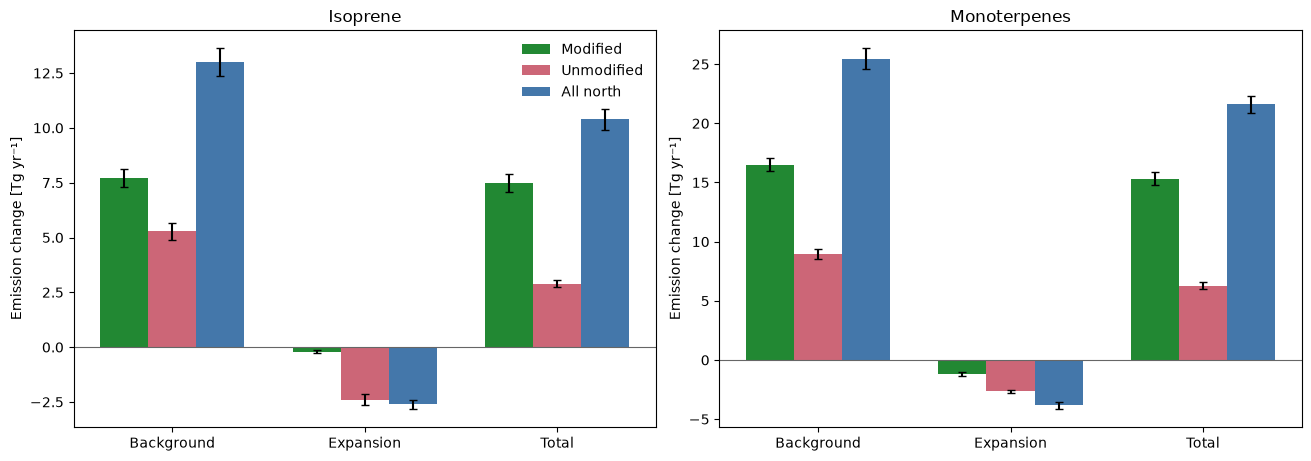

Isoprene expansion: modified -0.2131, unmodified -2.3936, all north -2.6067 Tg yr⁻¹
Monoterpenes expansion: modified -1.1856, unmodified -2.6594, all north -3.8450 Tg yr⁻¹


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
x, width = np.arange(len(COMPARISONS)), 0.25
region_colors = {"Modified": "#228833", "Unmodified": "#CC6677", "All north": "#4477AA"}
for ax, var in zip(axes, VARS):
    for i, region in enumerate(REGIONS):
        y = annual[var].sel(region=region, comparison=COMPARISONS)
        ax.bar(x + (i - 1) * width, y.mean("year"), width,
               yerr=y.std("year", ddof=1), capsize=3, label=region, color=region_colors[region])
    ax.axhline(0, color="0.4", linewidth=0.8)
    ax.set(title=LABELS[var], xticks=x, xticklabels=COMPARISONS, ylabel="Emission change [Tg yr⁻¹]")
axes[0].legend(frameon=False)
fig.savefig(OUT / "regional_budget_contributions.png", dpi=200)
plt.show()

for var in VARS:
    parts = annual[var].sel(comparison="Expansion").mean("year")
    m, u, total = [float(parts.sel(region=r)) for r in REGIONS]
    print(f"{LABELS[var]} expansion: modified {m:+.4f}, unmodified {u:+.4f}, all north {total:+.4f} Tg yr⁻¹")


## 6. Annual consistency
Look for persistent signs and whether the northern signal is dominated by modified cells or by the larger surrounding area. Simulation years are time-slice sampling years, not a transient future trajectory.

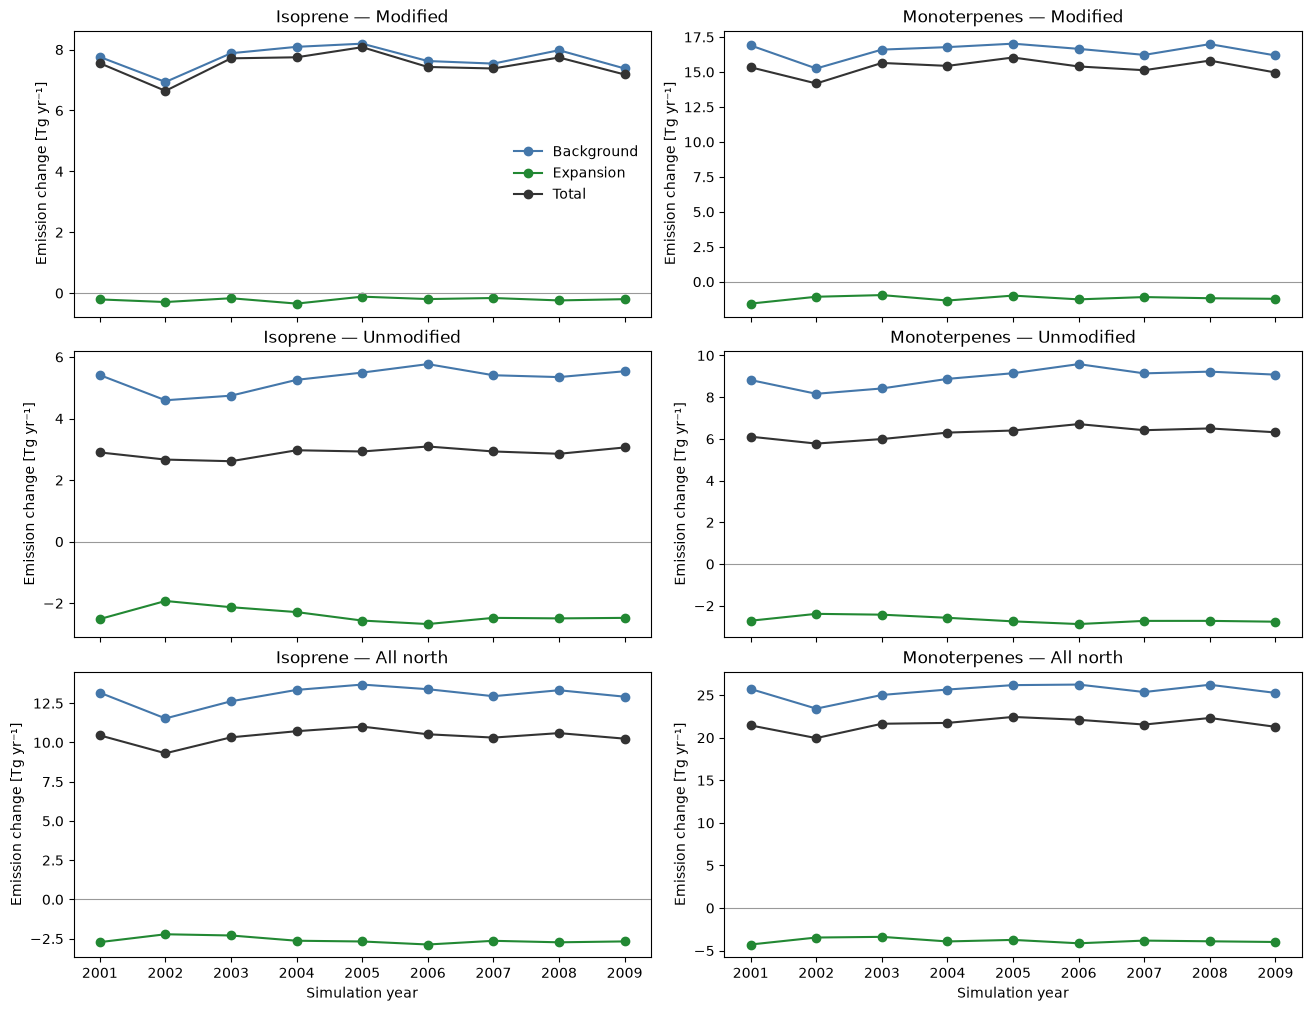

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        for name in COMPARISONS:
            values = annual[var].sel(region=region, comparison=name)
            ax.plot(values.year, values, "o-", color=COLORS[name], label=name)
        ax.axhline(0, color="0.6", linewidth=0.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Emission change [Tg yr⁻¹]")
        if i == 2:
            ax.set_xlabel("Simulation year")
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "annual_changes_three_regions.png", dpi=200)
plt.show()


## 7. Seasonal mean fluxes
Each mean uses its own region's area denominator. A stronger modified-cell mean does not necessarily imply a larger regional total. The y-scale is shared across regions for each species.

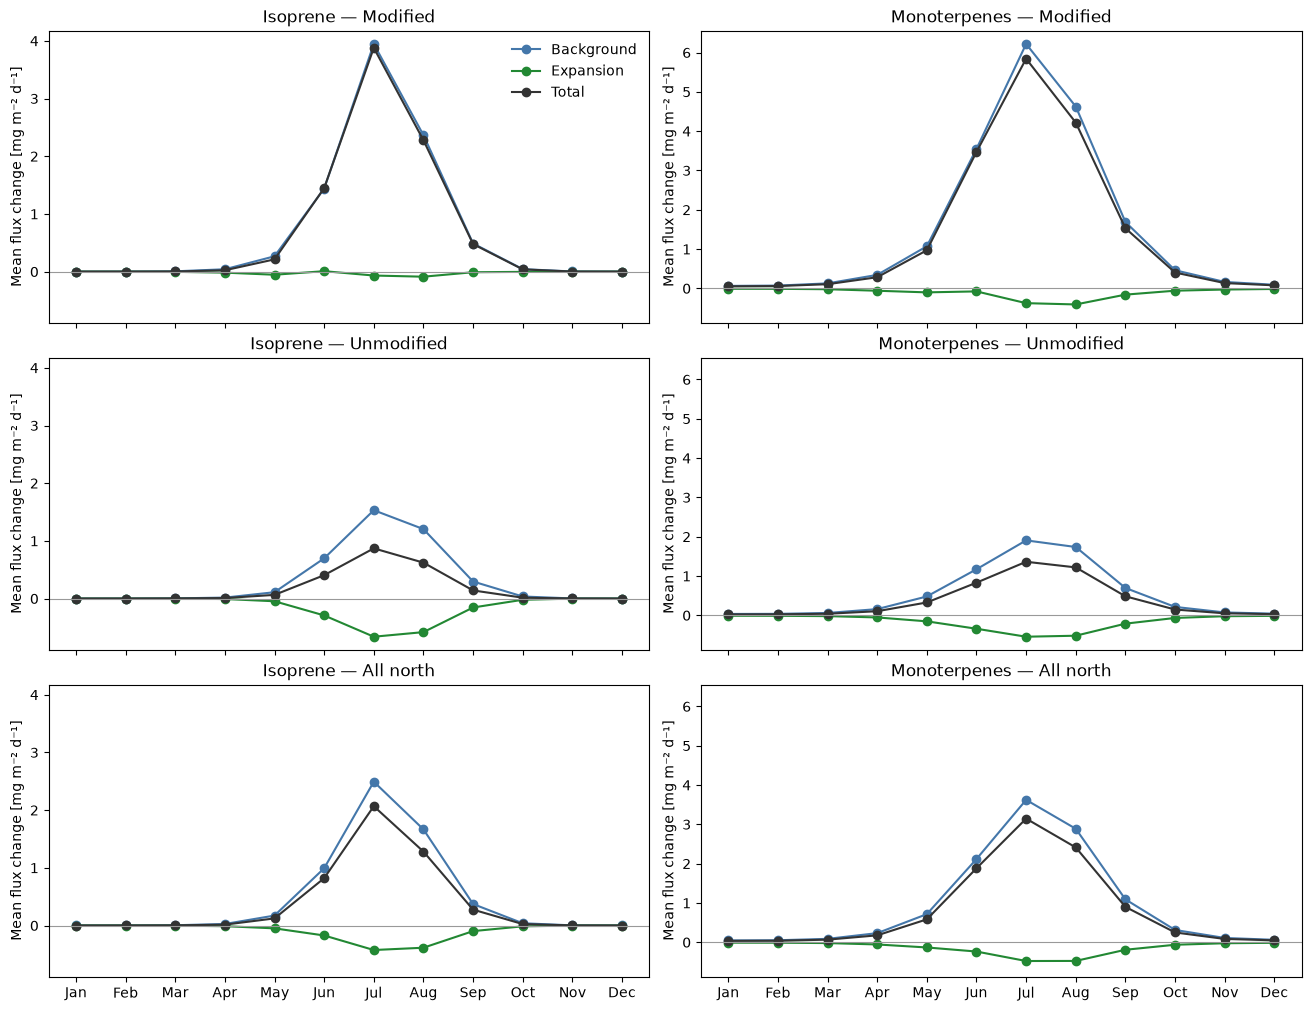

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, sharey="col", constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        for name in COMPARISONS:
            values = seasonal[var].sel(region=region, comparison=name)
            ax.plot(values.month, values, "o-", color=COLORS[name], label=name)
        ax.axhline(0, color="0.6", linewidth=0.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Mean flux change [mg m⁻² d⁻¹]",
               xticks=range(1, 13), xticklabels=list(calendar.month_abbr)[1:])
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "seasonality_three_regions.png", dpi=200)
plt.show()


## 8. Check cancellation within each region
Positive and negative annual-mean grid-cell changes are integrated separately. Their sum equals the net regional change. This diagnoses **spatial** cancellation after time averaging; it does not measure seasonal cancellation at a cell.

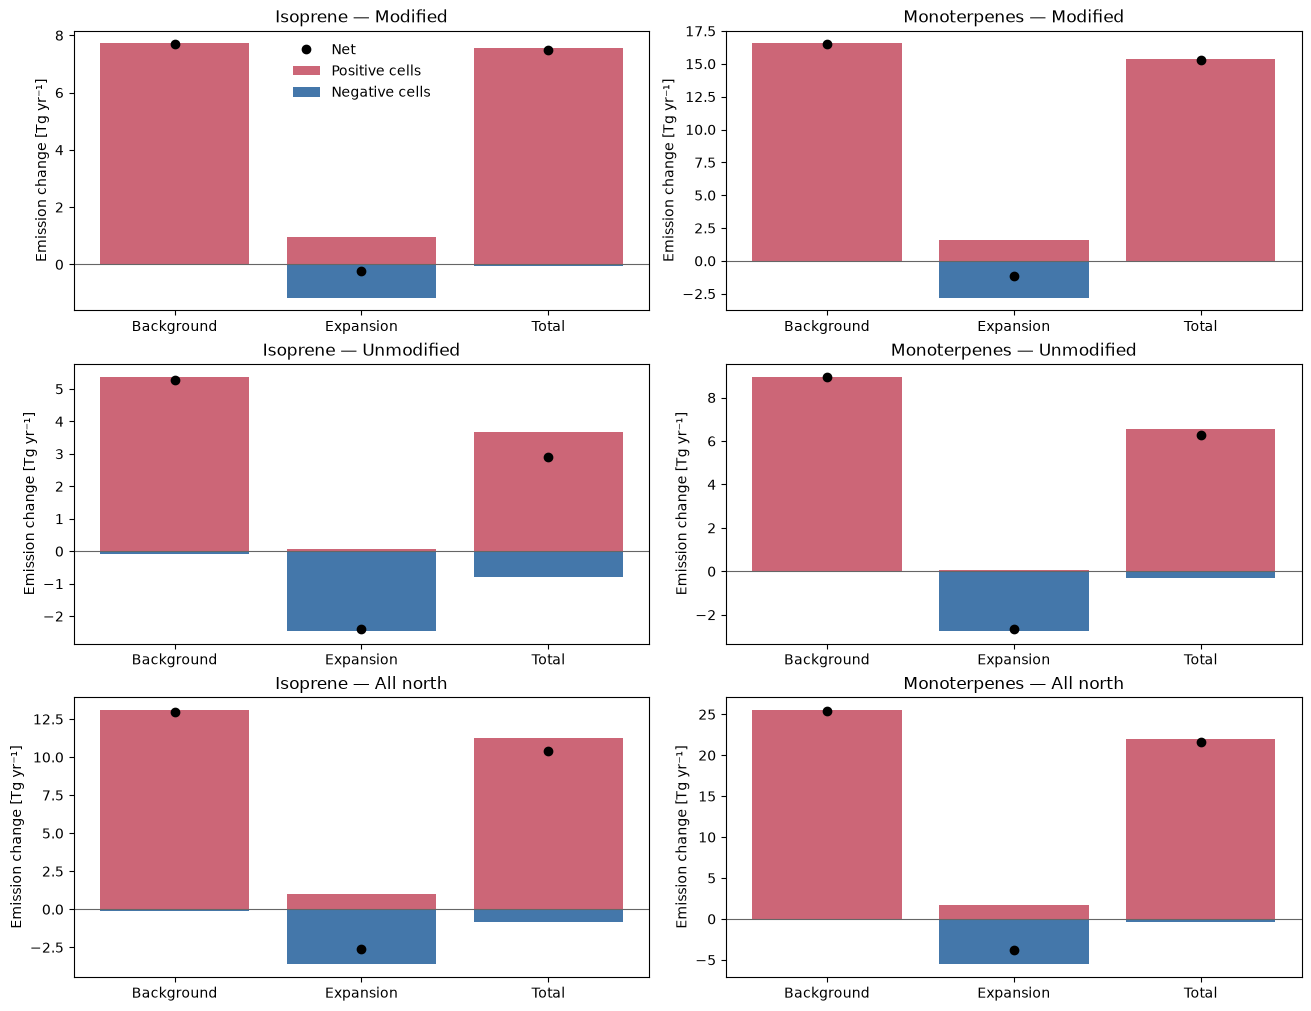

In [9]:
mean_annual_mass = (xr.concat(list(delta.values()), pd.Index(COMPARISONS, name="comparison")) *
                    seconds / 1e9).groupby("year").sum("time").mean("year")
positive = (mean_annual_mass.clip(min=0) * region_weights).sum(("lat", "lon"))
negative = (mean_annual_mass.clip(max=0) * region_weights).sum(("lat", "lon"))
net = annual.sel(comparison=COMPARISONS).mean("year")
xr.testing.assert_allclose(positive + negative, net)

cancellation = xr.concat([positive, negative, net], pd.Index(["Positive", "Negative", "Net"], name="component"))
cancellation.to_dataframe().to_csv(OUT / "spatial_cancellation_three_regions.csv")
fig, axes = plt.subplots(3, 2, figsize=(13, 10), constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        ax.bar(COMPARISONS, positive[var].sel(region=region), color="#CC6677", label="Positive cells")
        ax.bar(COMPARISONS, negative[var].sel(region=region), color="#4477AA", label="Negative cells")
        ax.plot(COMPARISONS, net[var].sel(region=region), "ko", label="Net")
        ax.axhline(0, color="0.4", linewidth=0.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Emission change [Tg yr⁻¹]")
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "spatial_cancellation_three_regions.png", dpi=200)
plt.show()


## 9. Optional region map
Green = modified; grey = unmodified. Both are restricted to the northern domain. Cartopy may need a pre-populated coastline cache on an offline cluster.

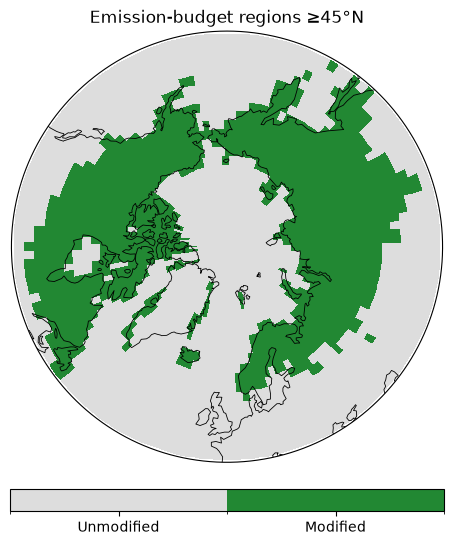

In [10]:
if RUN_MAPS:
    import cartopy.crs as ccrs
    from cartopy.util import add_cyclic_point
    from matplotlib.colors import ListedColormap
    from matplotlib.path import Path as MplPath
    
    classes = xr.where(modified, 1, 0).where(north).transpose("lat", "lon")
    cyclic, longitude = add_cyclic_point(classes.values, coord=classes.lon.values)
    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": ccrs.NorthPolarStereo()})
    mesh = ax.pcolormesh(longitude, classes.lat, cyclic, transform=ccrs.PlateCarree(),
                         cmap=ListedColormap(["#dddddd", "#228833"]),
                         norm=BoundaryNorm([-0.5, 0.5, 1.5], 2), shading="auto")
    theta = np.linspace(0, 2 * np.pi, 200)
    circle = MplPath(np.column_stack([np.sin(theta), np.cos(theta)]) * 0.5 + 0.5)
    ax.set_boundary(circle, transform=ax.transAxes)
    ax.set_extent([-180, 180, MIN_LAT, 90], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.6)
    ax.set_title(f"Emission-budget regions ≥{MIN_LAT}°N")
    cb = fig.colorbar(mesh, ax=ax, orientation="horizontal", ticks=[0, 1], shrink=0.8, pad=0.05)
    cb.ax.set_xticklabels(["Unmodified", "Modified"])
    fig.savefig(OUT / "region_mask.png", dpi=200, bbox_inches="tight")
    plt.show()


## 9b. Background, expansion and total maps
Annual-mean flux change for each comparison. Each species uses one common discrete colour scale across the three maps, with zero inside the white bin, so the white bin does not mean exactly zero. Section 12 repeats the expansion map on a narrower scale.

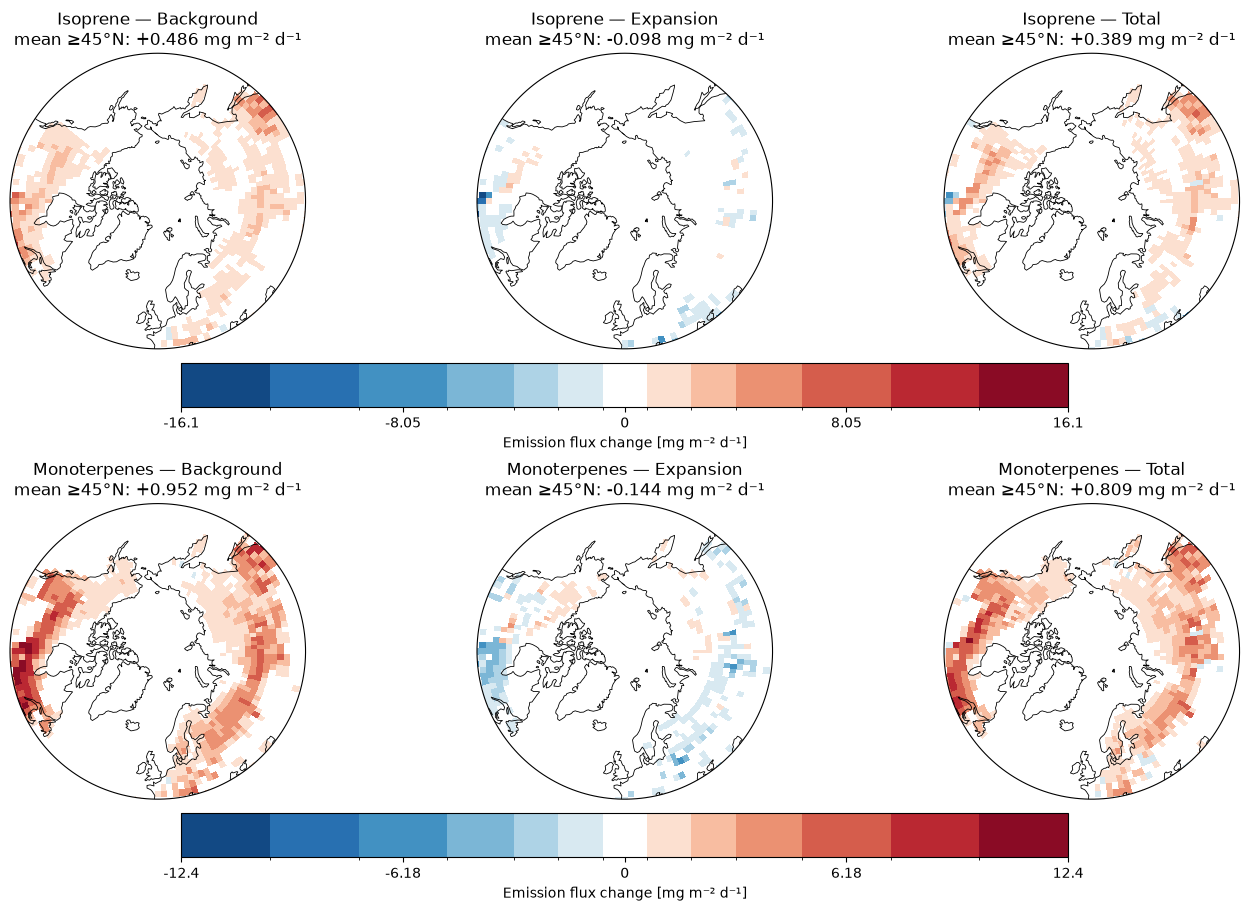

In [11]:
if RUN_MAPS:
    import cartopy.crs as ccrs
    from cartopy.util import add_cyclic_point
    from matplotlib.colors import ListedColormap, BoundaryNorm
    from matplotlib.path import Path as MplPath
    from matplotlib.ticker import FormatStrFormatter

    weights = region_weights.sel(region="All north", drop=True)
    maps = {name: (ds * seconds).sum("time") / seconds.sum() * 86400 * 1e6
            for name, ds in delta.items()}

    # Six negative bins, one white bin around zero, six positive bins.
    base = plt.get_cmap("RdBu_r")
    colors = np.vstack([base(np.linspace(0.05, 0.42, 6)),
                        [1, 1, 1, 1],
                        base(np.linspace(0.58, 0.95, 6))])
    cmap = ListedColormap(colors)
    relative_bounds = np.array([-1, -.8, -.6, -.4, -.25, -.15, -.05,
                                .05, .15, .25, .4, .6, .8, 1])

    theta = np.linspace(0, 2 * np.pi, 200)
    circle = MplPath(np.column_stack([np.sin(theta), np.cos(theta)]) * 0.5 + 0.5)
    fig, axes = plt.subplots(2, 3, figsize=(14, 9),
                             subplot_kw={"projection": ccrs.NorthPolarStereo()}, constrained_layout=True)

    for row, var in enumerate(VARS):
        limit = max(float(abs(ds[var].where(ds.lat >= MIN_LAT)).max()) for ds in maps.values())
        limit = max(limit, 1e-12)
        levels = relative_bounds * limit
        norm = BoundaryNorm(levels, cmap.N)

        for col, (name, ds) in enumerate(maps.items()):
            ax = axes[row, col]
            field = ds[var].transpose("lat", "lon")
            cyclic, longitude = add_cyclic_point(field.values, coord=field.lon.values)
            mesh = ax.pcolormesh(longitude, field.lat, cyclic, transform=ccrs.PlateCarree(),
                                 cmap=cmap, norm=norm, shading="auto")
            ax.set_extent([-180, 180, MIN_LAT, 90], crs=ccrs.PlateCarree())
            ax.set_boundary(circle, transform=ax.transAxes)
            ax.coastlines(linewidth=0.6)
            mean = float((field * weights).sum() / weights.sum())
            ax.set_title(f"{LABELS[var]} — {name}\nmean ≥{MIN_LAT}°N: {mean:+.3f} mg m⁻² d⁻¹")

        fig.colorbar(mesh, ax=list(axes[row]), orientation="horizontal", shrink=0.8,
                 pad=0.04, spacing="proportional", ticks=np.linspace(-limit, limit, 5),
                 format=FormatStrFormatter("%.3g"),
                 label="Emission flux change [mg m⁻² d⁻¹]")

    fig.savefig(OUT / "emissions_decomposition_maps.png", dpi=200)
    plt.show()

## Reading the results

1. Start with regional budget contributions. Does the negative expansion total arise within modified cells, outside them, or both?
2. Compare regional totals with mean fluxes. Large unmodified-area totals can arise from small flux changes over a large area.
3. Use the seasonal curves to locate the active months, and annual curves to check sign consistency.
4. Inspect the cancellation panels before describing a region as uniformly increasing or decreasing.
5. An expansion contrast outside modified cells can reflect environmental adjustments; these plots alone do not establish their mechanism or exclude other simulation differences.
6. Modified-cell results include all processes operating there. They are not a direct PFT-only attribution.
7. Error bars show interannual SD, not formal significance. Cloud/aerosol/radiation effects should still be evaluated over a wider domain.
8. The prescribed-PD experiment's emissions should be checked against realised SFISOP/SFMTERP if exact correspondence with this interactive-run decomposition is needed.

All CSVs and figures are saved in the single OUT folder configured above. No extra data loading is needed when rerunning plots.

## 10. Conclusions from the northern decomposition

For 2001–2009, emissions north of 45°N increase strongly between CTRL_PD and CTRL_FUT. The imposed vegetation change partly offsets this increase: LCC_FUT emits less isoprene and monoterpenes than CTRL_FUT, while remaining above CTRL_PD.

### Quantitative results

| Contribution [Tg yr⁻¹] | Isoprene | Monoterpenes |
|---|---:|---:|
| Background: CTRL_FUT − CTRL_PD | +12.99 | +25.45 |
| Expansion: LCC_FUT − CTRL_FUT | −2.61 | −3.85 |
| Total: LCC_FUT − CTRL_PD | +10.39 | +21.61 |

The vegetation perturbation reduces emissions relative to CTRL_FUT by approximately **11.7% for isoprene** and **11.4% for monoterpenes**. It offsets approximately **20% and 15%**, respectively, of the background-driven increases.

“Background” includes all environmental differences between the control simulations; it cannot be attributed to temperature alone.

### Seasonal, annual and spatial behaviour

- Background increases peak in July, while the negative expansion contributions are strongest in July–August. The vegetation perturbation primarily reduces the summer increase.
- Background contributions are positive and expansion contributions negative in every analysed year. Their signs are consistent across the nine-year sample; the plotted standard deviations are not formal significance tests.
- Expansion produces both positive and negative local changes. A negative regional budget does not imply a decrease in every modified cell.
- The common map scale facilitates comparison of magnitudes but hides weaker changes. The white interval spans approximately ±0.805 mg m⁻² d⁻¹ for isoprene and ±0.618 mg m⁻² d⁻¹ for monoterpenes; white therefore does not mean zero.

### Implications for the fixed-BVOC experiments

The total regional mean flux changes, +0.389 mg m⁻² d⁻¹ for isoprene and +0.809 mg m⁻² d⁻¹ for monoterpenes, agree to the displayed precision with the original LCC_FUT − LCC_FUT_fBVOCctrlPD_IM maps.

The positive northern emissions contrast in that experiment is therefore dominated by background environmental change, while the LCC contribution opposes it. The associated SOA and cloud responses should not be described as consequences of a regional BVOC emissions increase caused by forest expansion.

This experiment measures the response to allowing emissions to reach their future, expanded-vegetation state instead of prescribing present-day control emissions. The emissions decomposition does **not** partition the cloud or radiative response, which need not be linear.

### Next steps (addressed in sections 3–9 and 11–17)

1. **Identify where the negative expansion contribution originates.**  
   Compare modified cells, unmodified cells north of 45°N, and the full northern domain. Restrict the modified-cell region to the same latitude domain so the two component budgets sum exactly to the northern total. Compare both integrated emissions and area-mean fluxes.

2. **Investigate spatial cancellation.**  
   Quantify positive and negative contributions separately within each region. Plot the expansion contrast with a narrower colour scale to identify features concealed by the shared scale.

3. **Investigate the mechanism of the decrease.**  
   In the regions contributing most to the negative expansion budget, compare PFT fractions, LAI, relevant temperature and radiation fields, and available MEGAN diagnostics. The current results do not distinguish changes in vegetation emission capacity from vegetation-induced environmental responses.

4. **Use a future emissions reference to isolate the future LCC-related atmospheric response.**  
   Compare LCC_FUT with LCC_FUT_fBVOCctrlFUT, prescribing emissions from CTRL_FUT. Retain LCC_FUT_fBVOCctrlPD_IM for the broader comparison against present-day emissions. Check realised SFISOP/SFMTERP in the fixed-emission runs to verify the intended contrasts.

5. **Evaluate atmospheric effects over a wider domain.**  
   Modified cells are useful for investigating emissions, but SOA, clouds and radiation can respond beyond that footprint. Use the aerosol, cloud and SW/LW radiative diagnostics to establish the atmospheric response; its sign cannot be inferred from the regional emissions total alone.

**Working conclusion:** In these simulations, future background conditions strongly increase northern isoprene and monoterpene emissions, while the imposed vegetation change partly offsets those increases. The location and mechanism of this negative LCC contribution remain to be established.

## 11. Where does the negative expansion contribution originate?
Ranks annual-mean negative grid-cell contributions, including cell area. Hotspots supply 80% of the gross decrease. They are outcome-selected, species-specific diagnostic regions, not independent evidence of mechanism.

Isoprene: 194 cells supply 80% of gross decrease: 78 modified and 116 unmodified.


,lat,lon,change_Tg_yr,gross_decrease_Tg_yr,cumulative_fraction
0,46.42105,267.5,-0.23727,0.23727,0.06570
1,46.42105,270.0,-0.17721,0.17721,0.11476
2,46.42105,15.0,-0.10005,0.10005,0.14246
3,48.31579,267.5,-0.09805,0.09805,0.16961
4,48.31579,25.0,-0.05283,0.05283,0.18424
5,46.42105,2.5,-0.04981,0.04981,0.19803
6,50.21053,82.5,-0.04619,0.04619,0.21082
7,52.10526,27.5,-0.03807,0.03807,0.22136
8,55.89474,100.0,-0.03684,0.03684,0.23156
9,52.10526,30.0,-0.03428,0.03428,0.24105


Monoterpenes: 191 cells supply 80% of gross decrease: 108 modified and 83 unmodified.


,lat,lon,change_Tg_yr,gross_decrease_Tg_yr,cumulative_fraction
0,46.42105,267.5,-0.08175,0.08175,0.01478
1,52.10526,27.5,-0.06955,0.06955,0.02735
2,48.31579,267.5,-0.06842,0.06842,0.03972
3,48.31579,25.0,-0.06836,0.06836,0.05207
4,48.31579,275.0,-0.06765,0.06765,0.06430
5,55.89474,100.0,-0.06718,0.06718,0.07644
6,48.31579,277.5,-0.06517,0.06517,0.08822
7,55.89474,82.5,-0.06498,0.06498,0.09997
8,46.42105,270.0,-0.06401,0.06401,0.11154
9,50.21053,270.0,-0.06034,0.06034,0.12245


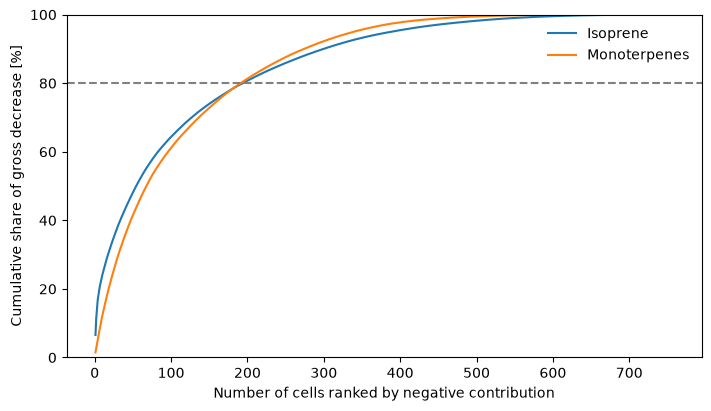

In [12]:
hotspots, ranked_cells = {}, {}
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for var in VARS:
    contribution = (mean_annual_mass[var].sel(comparison="Expansion", drop=True) * area).where(north)
    table = contribution.to_dataframe(name="change_Tg_yr").reset_index()
    table = table.loc[table.change_Tg_yr < 0].sort_values("change_Tg_yr").reset_index(drop=True)
    if table.empty:
        print(f"{LABELS[var]}: no negative annual-mean cells.")
        continue
    table["gross_decrease_Tg_yr"] = -table.change_Tg_yr
    table["cumulative_fraction"] = table.gross_decrease_Tg_yr.cumsum() / table.gross_decrease_Tg_yr.sum()
    n80 = int(np.searchsorted(table.cumulative_fraction.values, .8) + 1)
    hot = xr.zeros_like(modified, dtype=bool)
    for row in table.iloc[:n80].itertuples():
        hot.loc[dict(lat=row.lat, lon=row.lon)] = True
    hotspots[var], ranked_cells[var] = hot, table
    table.to_csv(OUT / f"{var}_negative_cells_ranked.csv", index=False)
    n_modified = int((hot & modified).sum())
    print(f"{LABELS[var]}: {n80} cells supply 80% of gross decrease: "
          f"{n_modified} modified and {n80 - n_modified} unmodified.")
    display(table.head(10).round(5))
    ax.plot(np.arange(1, len(table) + 1), table.cumulative_fraction * 100, label=LABELS[var])
ax.axhline(80, color="0.5", linestyle="--")
ax.set(xlabel="Number of cells ranked by negative contribution",
       ylabel="Cumulative share of gross decrease [%]", ylim=(0, 100))
if ranked_cells:
    ax.legend(frameon=False)
fig.savefig(OUT / "negative_contribution_concentration.png", dpi=200)
plt.show()

## 12. Expansion maps on a narrower scale (optional Cartopy)
Each species uses its 98th percentile of absolute northern flux change as its colour limit. Extreme cells saturate; colourbar extensions indicate this. White is ±5% of that limit. Green contours indicate modified cells.

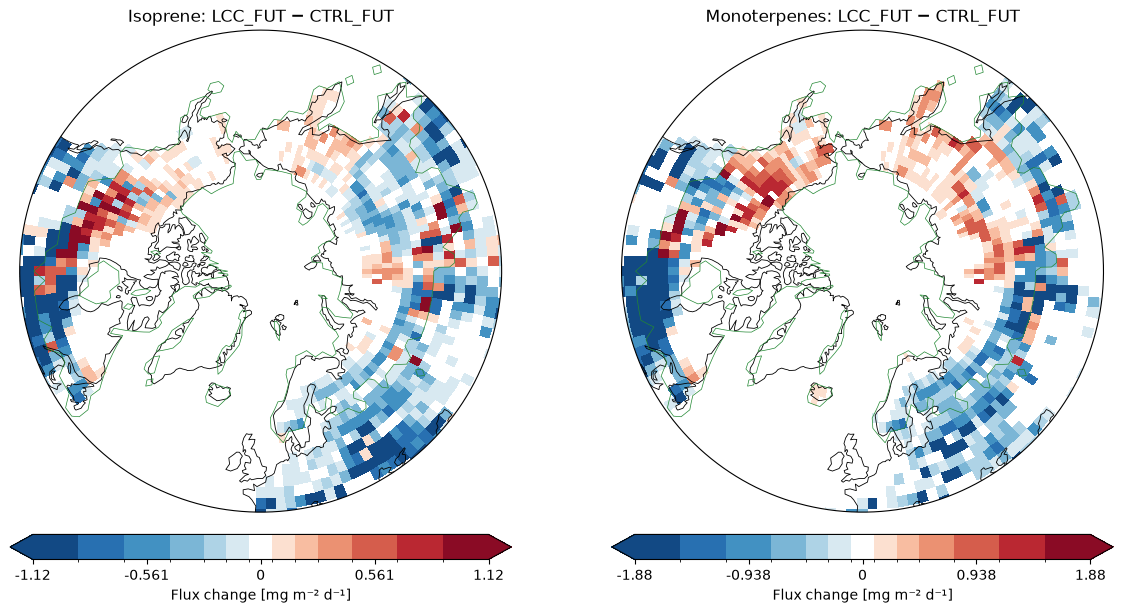

In [13]:
if RUN_MAPS:
    import cartopy.crs as ccrs
    from cartopy.util import add_cyclic_point
    from matplotlib.colors import ListedColormap, BoundaryNorm
    from matplotlib.path import Path as MplPath
    from matplotlib.ticker import FormatStrFormatter

    expansion_maps = (delta["Expansion"] * seconds).sum("time") / seconds.sum() * 86400 * 1e6
    base = plt.get_cmap("RdBu_r")
    cmap = ListedColormap(np.vstack([base(np.linspace(.05, .42, 6)), [1, 1, 1, 1],
                                     base(np.linspace(.58, .95, 6))]))
    fractions = np.array([-1, -.8, -.6, -.4, -.25, -.15, -.05, .05, .15, .25, .4, .6, .8, 1])
    theta = np.linspace(0, 2 * np.pi, 200)
    circle = MplPath(np.column_stack([np.sin(theta), np.cos(theta)]) * .5 + .5)
    fig, axes = plt.subplots(1, 2, figsize=(12, 6),
                             subplot_kw={"projection": ccrs.NorthPolarStereo()}, constrained_layout=True)
    for ax, var in zip(axes, VARS):
        field = expansion_maps[var].transpose("lat", "lon")
        limit = max(float(np.nanquantile(np.abs(field.where(north).values), .98)), 1e-12)
        cyclic, longitude = add_cyclic_point(field.values, coord=field.lon.values)
        mesh = ax.pcolormesh(longitude, field.lat, cyclic, cmap=cmap,
                             norm=BoundaryNorm(fractions * limit, cmap.N),
                             transform=ccrs.PlateCarree(), shading="auto")
        mask_cyclic, _ = add_cyclic_point(modified.transpose("lat", "lon").values.astype(float),
                                          coord=field.lon.values)
        ax.contour(longitude, field.lat, mask_cyclic, levels=[.5], colors=["#228833"],
                   linewidths=.5, transform=ccrs.PlateCarree())
        ax.set_extent([-180, 180, MIN_LAT, 90], crs=ccrs.PlateCarree())
        ax.set_boundary(circle, transform=ax.transAxes)
        ax.coastlines(linewidth=.6)
        ax.set_title(f"{LABELS[var]}: LCC_FUT − CTRL_FUT")
        fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=.85, pad=.04,
                     extend="both", spacing="proportional", ticks=np.linspace(-limit, limit, 5),
                     format=FormatStrFormatter("%.3g"), label="Flux change [mg m⁻² d⁻¹]")
    fig.savefig(OUT / "expansion_maps_narrow_scale.png", dpi=200)
    plt.show()

## 13. Additional inputs
Paths for sections 14–17, filled from the cluster archive. TREFHT is 2-m air temperature, not MEGAN leaf temperature; CLM `TV` (vegetation temperature) is the closer proxy. Additional fields must be monthly 2D gridded fields with time bounds on the CAM grid.

`LCC_FUT_fBVOCctrlFUT` has not been run, so section 16 checks only the PD-prescribed run and section 17 shows only the full contrast LCC_FUT − LCC_FUT_fBVOCctrlPD_IM. That contrast mixes the future background with the LCC effect on emissions (see CLAUDE.md).

In [14]:
A = "/cluster/home/adelez/BRL-FRST-XPSN_archive"
CLM_FILES = {"CTRL_FUT": FILES["CTRL_FUT"].replace("/atm/", "/lnd/").replace("cam.h0", "clm2.h0"),
             "LCC_FUT": FILES["LCC_FUT"].replace("/atm/", "/lnd/").replace("cam.h0", "clm2.h0")}
FIXED_PD_IM = f"{A}/NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOC_f19_f19-20261009/atm/hist/*.cam.h0.*.nc"

RUN_MECHANISMS = True
MECHANISM_INPUTS = {
    "TREFHT": {"CTRL_FUT": FILES["CTRL_FUT"], "LCC_FUT": FILES["LCC_FUT"]},  # CAM 2-m air temperature
    "FSDS": {"CTRL_FUT": FILES["CTRL_FUT"], "LCC_FUT": FILES["LCC_FUT"]},    # CAM surface downwelling SW
    "TV": CLM_FILES,    # CLM vegetation temperature (closer to MEGAN leaf temperature than TREFHT)
    "TLAI": CLM_FILES,  # CLM total leaf area index
}
SURFDATA = {
    "CTRL_FUT": "/cluster/shared/noresm/inputdata/lnd/clm2/surfdata_map/release-clm5.0.18/surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c190304.nc",
    "LCC_FUT": "/cluster/shared/noresm/inputdata/lnd/clm2/surfdata_map/surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc",
}  # fsurdat from each case's CaseDocs/lnd_in
FIXED_FILES = {"LCC_FUT_fBVOCctrlPD_IM": FIXED_PD_IM, "LCC_FUT_fBVOCctrlFUT": None}  # FUT run not done yet
# Monthly 2D CAM h0 fields. cb_SOA_LV/SV are gas-phase SOA precursor columns (no condensed-SOA burden in h0).
ATM_VARIABLES = ["cb_ISOP", "cb_MTERP", "cb_SOA_LV", "cb_SOA_SV", "AOD_VIS", "CDNUMC", "ACTREL",
                 "TGCLDLWP", "CLDTOT", "SWCF", "LWCF", "FSNT", "FLNT"]
ATM_INPUTS = {v: {"variable": v, "paths": {"LCC_FUT": FILES["LCC_FUT"], "LCC_FUT_fBVOCctrlPD_IM": FIXED_PD_IM}}
              for v in ATM_VARIABLES}


In [15]:
def load_monthly_field(pattern, variable):
    paths = sorted(glob(str(Path(pattern).expanduser())))
    if not paths:
        raise FileNotFoundError(pattern)
    chunks, durations, units_seen = [], [], set()
    expected = reference.time.values
    for path in paths:
        with xr.open_dataset(path) as ds:
            if variable not in ds:
                raise KeyError(f"{variable} not found in {path}")
            bounds = ds.time.attrs.get("bounds")
            if not bounds or bounds not in ds:
                bounds = next((v for v in ("time_bnds", "time_bounds") if v in ds), None)
            if bounds is None:
                raise ValueError(f"{path}: complete monthly time bounds are required.")
            indices, keys, dt = [], [], []
            for i in range(ds.sizes["time"]):
                start, end = ds[bounds].isel(time=i).values.ravel()
                sy, sm, sd, sh, smin, ss = date_parts(start)
                ey, em, ed, eh, emin, es = date_parts(end)
                year, month, *_ = date_parts(start + (end - start) / 2)
                key = year * 100 + month
                if key not in expected:
                    continue
                if not (sd == ed == 1 and (ey, em) == (sy + (sm == 12), sm % 12 + 1)
                        and (sy, sm) == (year, month) and sh == smin == ss == eh == emin == es == 0):
                    raise ValueError(f"{path}: record {i} is not a complete month.")
                indices.append(i)
                keys.append(key)
                dt.append(seconds_between(start, end))
            if not indices:
                continue
            if set(ds[variable].dims) != {"time", "lat", "lon"}:
                raise ValueError(f"{variable}: expected time/lat/lon, got {ds[variable].dims}")
            units_seen.add(ds[variable].attrs.get("units", ""))
            chunks.append(ds[variable].isel(time=indices).assign_coords(time=keys).load())
            durations.append(xr.DataArray(dt, dims="time", coords={"time": keys}))
    if not chunks:
        raise ValueError(f"No selected months for {variable}.")
    field = xr.concat(chunks, dim="time", join="exact").sortby("time").sortby("lat").sortby("lon")
    dt = xr.concat(durations, dim="time").sortby("time")
    if not np.array_equal(field.time.values, expected):
        raise ValueError(f"{variable}: missing or duplicate months.")
    np.testing.assert_allclose(dt.values, seconds.values, rtol=0, atol=0)
    # CLM and CAM write the same grid with ~1e-13° differences: check, then use the CAM coordinates.
    np.testing.assert_allclose(field.lat.values, reference.lat.values, rtol=0, atol=1e-5)
    np.testing.assert_allclose(field.lon.values, reference.lon.values, rtol=0, atol=1e-5)
    field = field.assign_coords(lat=reference.lat, lon=reference.lon)
    if len(units_seen) != 1 or not next(iter(units_seen)):
        raise ValueError(f"{variable}: missing or inconsistent units: {units_seen}")
    field.attrs["units"] = next(iter(units_seen))
    return field.assign_coords(year=reference.year, month=reference.month)

def regional_series(field, mask):
    finite = np.isfinite(field)
    always_valid, ever_valid = finite.all("time"), finite.any("time")
    if bool(((always_valid != ever_valid) & mask).any()):
        raise ValueError("Time-varying missing values inside the selected region.")
    w = area.where(mask & always_valid, 0)
    if float(w.sum()) <= 0:
        raise ValueError("No valid area in this region.")
    return (field.where(finite, 0) * w).sum(("lat", "lon")) / w.sum()

def paired_difference(a, b):
    a, b = xr.align(a, b, join="exact")
    if a.attrs.get("units") != b.attrs.get("units"):
        raise ValueError("Units differ between paired fields.")
    if not bool((np.isfinite(a) == np.isfinite(b)).all()):
        raise ValueError("Paired fields have different missing-data footprints.")
    return a - b


## 14. Environmental controls in the main decrease regions
Plots seasonal contrasts and exports JJA means. Land-only fields use their valid land-cell footprint, so their area denominator can differ from that of CAM fields. Missing-data masks must match between cases and remain stable in time. Coincident changes are hypotheses for mechanism, not causal attribution.

Loading TREFHT
Loading FSDS
Loading TV
Loading TLAI


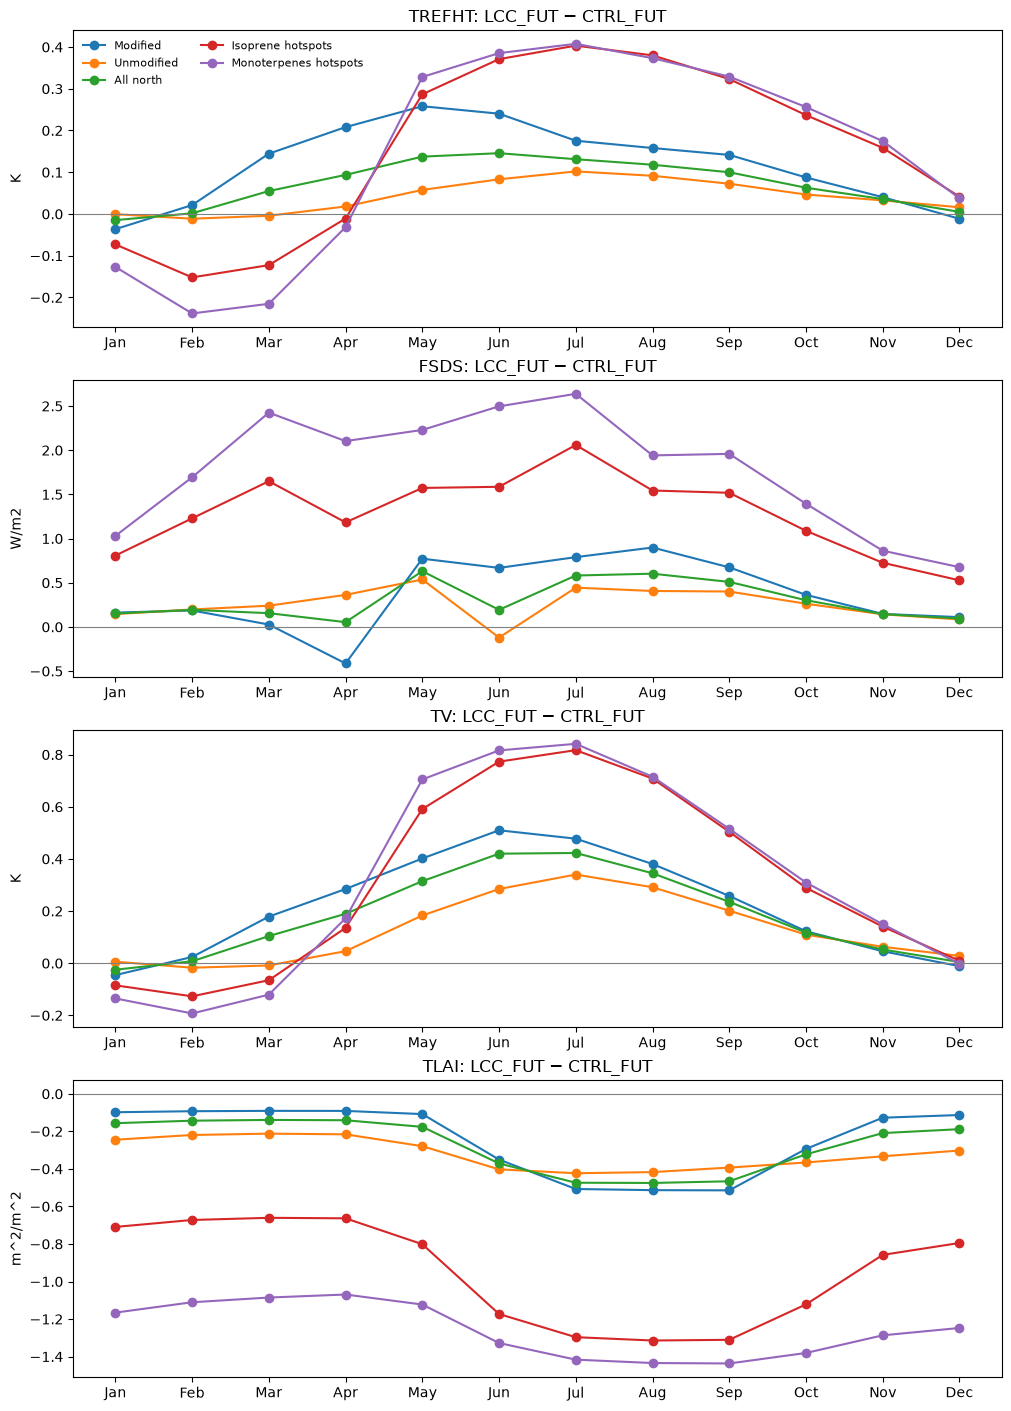

,variable,region,JJA_change,units
0,TREFHT,Modified,0.190738,K
1,TREFHT,Unmodified,0.092301,K
2,TREFHT,All north,0.131469,K
3,TREFHT,Isoprene hotspots,0.384967,K
4,TREFHT,Monoterpenes hotspots,0.388844,K
5,FSDS,Modified,0.786897,W/m2
6,FSDS,Unmodified,0.247552,W/m2
7,FSDS,All north,0.462156,W/m2
8,FSDS,Isoprene hotspots,1.731159,W/m2
9,FSDS,Monoterpenes hotspots,2.357161,W/m2


In [16]:
mechanism = {}
if RUN_MECHANISMS:
    for variable, paths in MECHANISM_INPUTS.items():
        print(f"Loading {variable}")
        mechanism[variable] = {case: load_monthly_field(pattern, variable) for case, pattern in paths.items()}
else:
    print("Mechanism loading skipped; set RUN_MECHANISMS=True to enable.")

diagnostic_masks = {r: region_masks.sel(region=r, drop=True) for r in REGIONS}
diagnostic_masks.update({f"{LABELS[var]} hotspots": mask for var, mask in hotspots.items()})
mechanism_rows = []
if mechanism:
    fig, axes = plt.subplots(len(mechanism), 1, figsize=(10, 3.5 * len(mechanism)),
                              squeeze=False, constrained_layout=True)
    for ax, (variable, pair) in zip(axes[:, 0], mechanism.items()):
        difference = paired_difference(pair["LCC_FUT"], pair["CTRL_FUT"])
        units = pair["CTRL_FUT"].attrs["units"]
        for name, mask in diagnostic_masks.items():
            series = regional_series(difference, mask)
            cycle = (series * seconds).groupby("month").sum() / seconds.groupby("month").sum()
            ax.plot(cycle.month, cycle, marker="o", label=name)
            jja = reference.month.isin([6, 7, 8])
            jja_mean = float((series * seconds).where(jja).sum() / seconds.where(jja).sum())
            mechanism_rows.append({"variable": variable, "region": name, "JJA_change": jja_mean, "units": units})
        ax.axhline(0, color="0.5", linewidth=.8)
        ax.set(title=f"{variable}: LCC_FUT − CTRL_FUT", ylabel=units,
               xticks=range(1, 13), xticklabels=list(calendar.month_abbr)[1:])
    axes[0, 0].legend(frameon=False, fontsize=8, ncol=2)
    fig.savefig(OUT / "mechanism_seasonal_changes.png", dpi=200)
    plt.show()
    mechanism_summary = pd.DataFrame(mechanism_rows)
    display(mechanism_summary)
    mechanism_summary.to_csv(OUT / "mechanism_JJA_changes.csv", index=False)


## 15. PFT-fraction changes (optional)
Uses the actual control and LCC surface datasets. Verifies their 2D geography before attaching CAM coordinates. This block expects the original grid order; if it differs it stops, rather than silently relabelling cells.

Reported values are whole-grid-area-weighted changes in **natural-PFT percentages**, not changes in PFT area (km²). PFT area calculation would additionally require the natural-vegetation fraction and the correct land-area basis.

In [17]:
if all(SURFDATA.values()):
    pft = {}
    for case, path in SURFDATA.items():
        with xr.open_dataset(path) as ds:
            field = ds["PCT_NAT_PFT"].load()
            rename = {d: new for d, new in {"lsmlat": "lat", "lsmlon": "lon"}.items() if d in field.dims}
            field = field.rename(rename)
            if "LATIXY" not in ds or "LONGXY" not in ds:
                raise ValueError("LATIXY/LONGXY required to verify the surfdata grid.")
            lat2, lon2 = ds.LATIXY.values, np.mod(ds.LONGXY.values, 360)
            expected_shape = (reference.sizes["lat"], reference.sizes["lon"])
            if lat2.shape != expected_shape or lon2.shape != expected_shape:
                raise ValueError("Surface-data grid dimensions do not match CAM.")
            np.testing.assert_allclose(lat2, np.broadcast_to(reference.lat.values[:, None], expected_shape), rtol=0, atol=1e-5)
            np.testing.assert_allclose(lon2, np.broadcast_to(reference.lon.values[None, :] % 360, expected_shape), rtol=0, atol=1e-5)
            pft[case] = field.assign_coords(lat=reference.lat, lon=reference.lon)
    ctrl, lcc = xr.align(pft["CTRL_FUT"], pft["LCC_FUT"], join="exact")
    change = lcc - ctrl
    w = region_weights.sel(region="Modified", drop=True)
    if not bool(np.isfinite(change.where(w > 0, 0)).all()):
        raise ValueError("Missing PFT fractions within modified cells.")
    mean_change = (change * w).sum(("lat", "lon")) / w.sum()
    pft_summary = mean_change.to_dataframe(name="mean_change_percentage_points")
    display(pft_summary)
    pft_summary.to_csv(OUT / "PFT_changes_modified_cells.csv")
else:
    print("PFT analysis skipped: set both SURFDATA paths.")


,mean_change_percentage_points
natpft,
0,-3.501225
1,0.000701
2,2.345383
3,2.828949
4,0.000000
5,0.000154
6,0.000000
7,0.651382
8,4.836425


## 16. Realised fixed emissions versus their source controls
Checks annual northern/regional budgets, annual-mean map RMSE and monthly seasonal-cycle differences. Climatology construction and interpolation can produce differences; inspect their size rather than assuming exact monthwise equivalence. Budget agreement alone can hide spatial discrepancies. No fixed-FUT result is fabricated if that experiment is unavailable.

Loading LCC_FUT_fBVOCctrlPD_IM


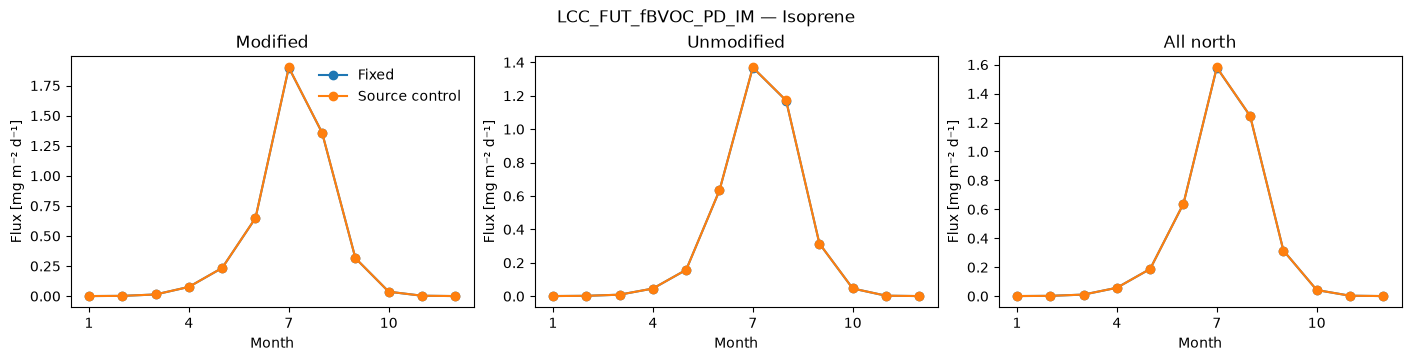

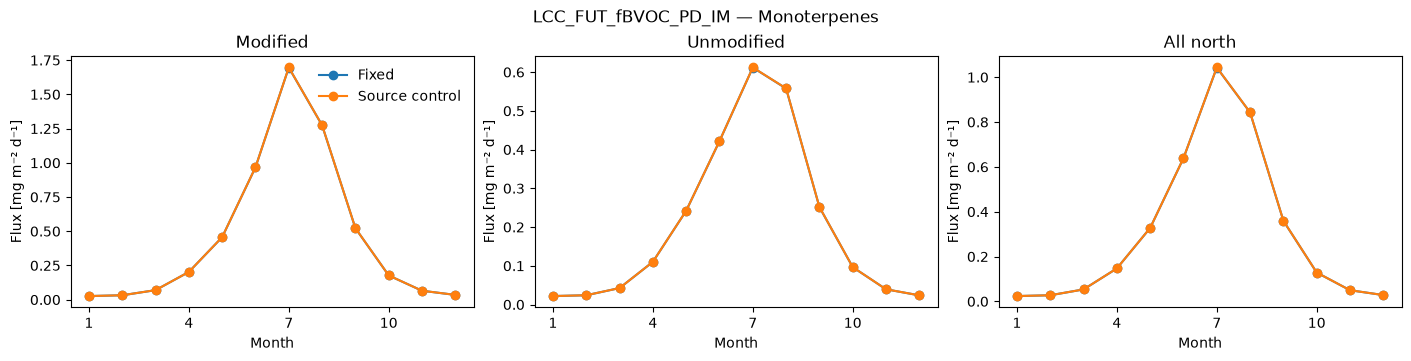

,case,species,region,fixed_Tg_yr,source_Tg_yr,difference_Tg_yr,difference_percent,mean_map_RMSE_mg_m2_day
0,LCC_FUT_fBVOCctrlPD_IM,Isoprene,Modified,4.11322,4.11518,-0.00195,-0.04745,0.00033
1,LCC_FUT_fBVOCctrlPD_IM,Isoprene,Unmodified,5.08796,5.09037,-0.00242,-0.04745,0.00040
2,LCC_FUT_fBVOCctrlPD_IM,Isoprene,All north,9.20118,9.20555,-0.00437,-0.04745,0.00037
3,LCC_FUT_fBVOCctrlPD_IM,Monoterpenes,Modified,4.93416,4.93650,-0.00234,-0.04742,0.00037
4,LCC_FUT_fBVOCctrlPD_IM,Monoterpenes,Unmodified,3.29927,3.30084,-0.00157,-0.04744,0.00025
5,LCC_FUT_fBVOCctrlPD_IM,Monoterpenes,All north,8.23344,8.23734,-0.00391,-0.04743,0.00030


In [18]:
fixed_emissions = {}
for alias, pattern in FIXED_FILES.items():
    if pattern:
        print(f"Loading {alias}")
        fixed_emissions[alias] = xr.Dataset({var: load_monthly_field(pattern, var) for var in VARS})
check_rows = []
for alias, fixed in fixed_emissions.items():
    source = fields["CTRL_FUT"] if alias.endswith("_FUT") else fields["CTRL_PD"]
    for var in VARS:
        unit = fixed[var].attrs.get("units", "").lower().replace(" ", "").replace("**", "^")
        if unit not in {"kg/m2/s", "kg/m^2/s", "kgm-2s-1", "kgm^-2s^-1"}:
            raise ValueError(f"{alias} {var}: expected kg m-2 s-1.")
        if not bool(np.isfinite(fixed[var]).all()):
            raise ValueError("Fixed emissions contain missing values.")
        fixed_mean = (fixed[var] * seconds).sum("time") / seconds.sum()
        source_mean = (source[var] * seconds).sum("time") / seconds.sum()
        fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
        for ax, region in zip(axes, REGIONS):
            w = region_weights.sel(region=region, drop=True)
            fixed_mass = float(((fixed[var] * w).sum(("lat", "lon")) * seconds / 1e9).groupby("year").sum().mean())
            source_mass = float(((source[var] * w).sum(("lat", "lon")) * seconds / 1e9).groupby("year").sum().mean())
            rmse = float(np.sqrt((((fixed_mean - source_mean) ** 2) * w).sum() / w.sum()))
            check_rows.append({"case": alias, "species": LABELS[var], "region": region,
                               "fixed_Tg_yr": fixed_mass, "source_Tg_yr": source_mass,
                               "difference_Tg_yr": fixed_mass - source_mass,
                               "difference_percent": 100 * (fixed_mass - source_mass) / source_mass if source_mass else np.nan,
                               "mean_map_RMSE_mg_m2_day": rmse * 86400 * 1e6})
            for label, field in [("Fixed", fixed[var]), ("Source control", source[var])]:
                series = (field * w).sum(("lat", "lon")) / w.sum() * 86400 * 1e6
                cycle = (series * seconds).groupby("month").sum() / seconds.groupby("month").sum()
                ax.plot(cycle.month, cycle, "o-", label=label)
            ax.set(title=region, xlabel="Month", ylabel="Flux [mg m⁻² d⁻¹]", xticks=[1, 4, 7, 10])
        axes[0].legend(frameon=False)
        fig.suptitle(f"{alias} — {LABELS[var]}")
        fig.savefig(OUT / f"fixed_check_{alias}_{var}.png", dpi=200)
        plt.show()
if check_rows:
    fixed_check = pd.DataFrame(check_rows)
    display(fixed_check.round(5))
    fixed_check.to_csv(OUT / "fixed_emissions_vs_source.csv", index=False)
else:
    print("Fixed-emission checks skipped: no files configured.")


## 17. Atmospheric response decomposition over the northern domain
Configure existing monthly 2D SOA/cloud/radiation diagnostics. This notebook does not reconstruct SOA burdens, cloud-conditioned diagnostics, or Ghan terms from incomplete inputs. Use correctly processed fields with their proper units.

With both fixed-reference runs:
- LCC emissions effect = LCC_FUT − LCC_FUT_fBVOCctrlFUT.
- PD→FUT prescribed emissions effect = LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD_IM.
- Full contrast = LCC_FUT − LCC_FUT_fBVOCctrlPD_IM.

Both fixed-reference simulations have expanded vegetation and the future environment. The exact algebraic identity is specific to this sequence; it is not a claim of linear atmospheric response. Interactive versus prescribed emissions may also differ in temporal variability. If only the prescribed-PD run is configured, its full contrast is still plotted.

Prioritise SOA burden, droplet number/radius, liquid water path and SW/LW diagnostics separately. Use Ghan diagnostics for the corresponding aerosol radiative attribution; ordinary CRE differences are not automatically aerosol-cloud forcing. Consider global or additional latitude bands as a subsequent check for responses beyond 45°N.

Loading cb_ISOP
Loading cb_MTERP
Loading cb_SOA_LV
Loading cb_SOA_SV
Loading AOD_VIS
Loading CDNUMC
Loading ACTREL
Loading TGCLDLWP
Loading CLDTOT
Loading SWCF
Loading LWCF
Loading FSNT
Loading FLNT


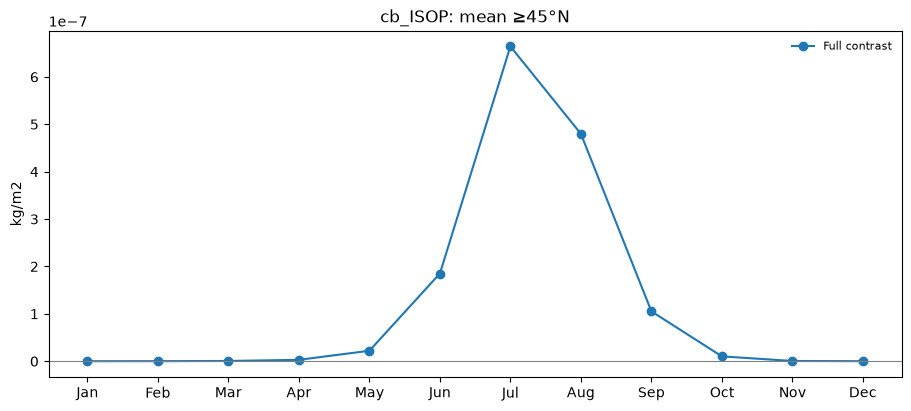

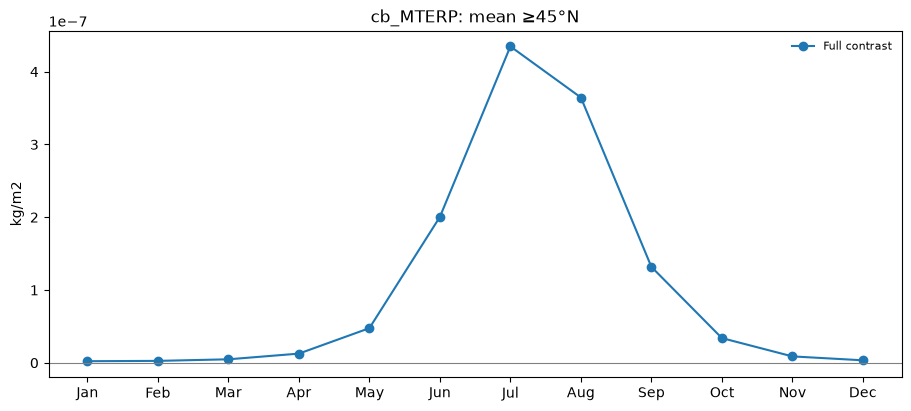

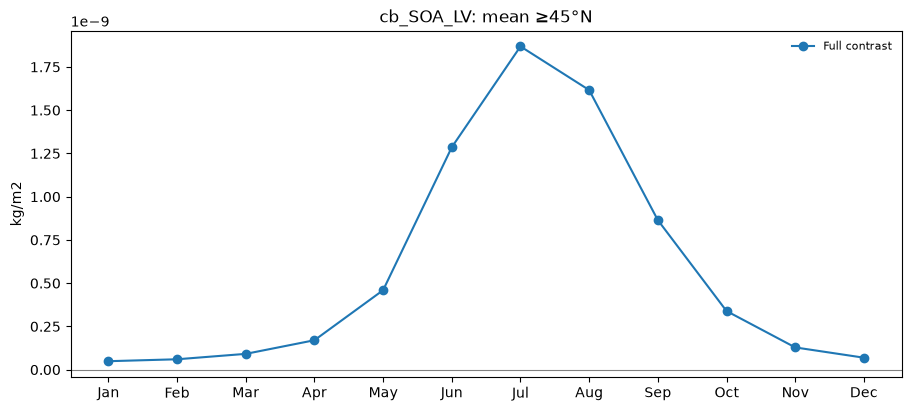

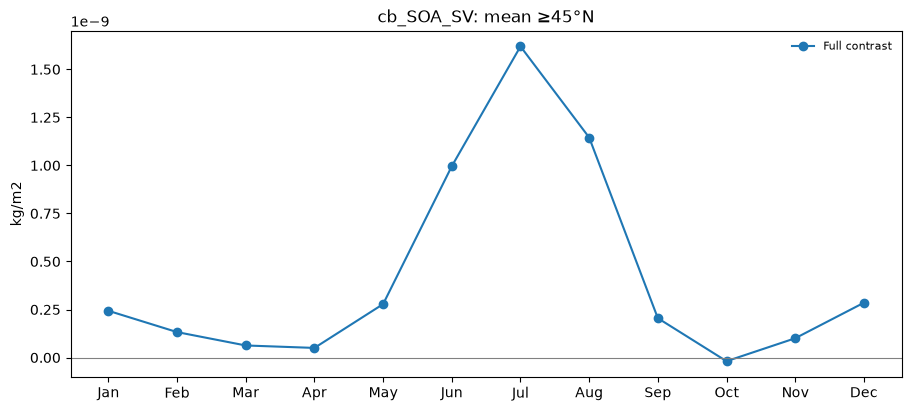

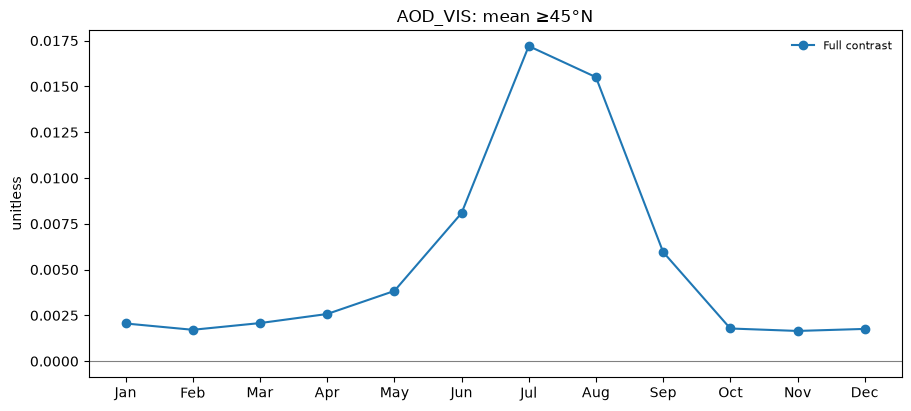

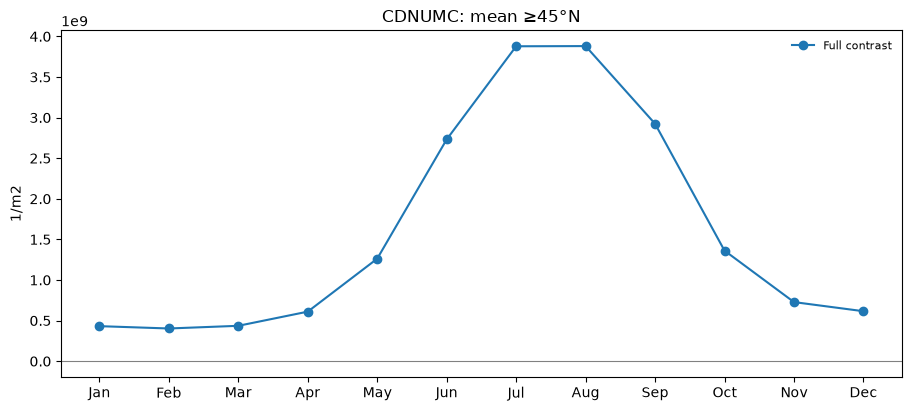

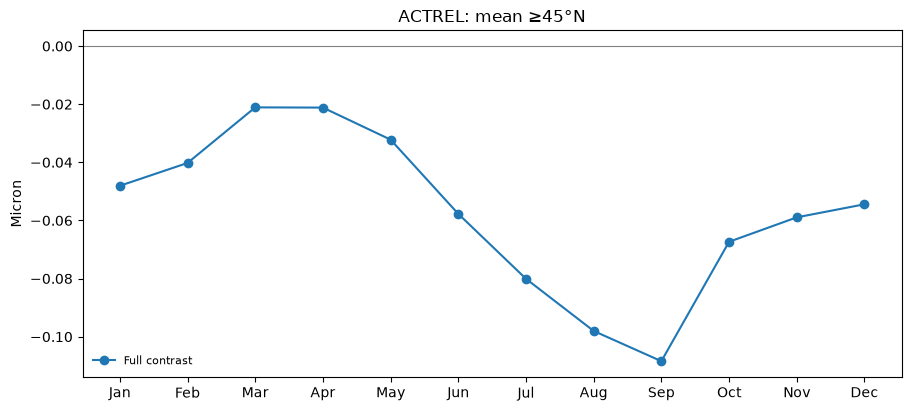

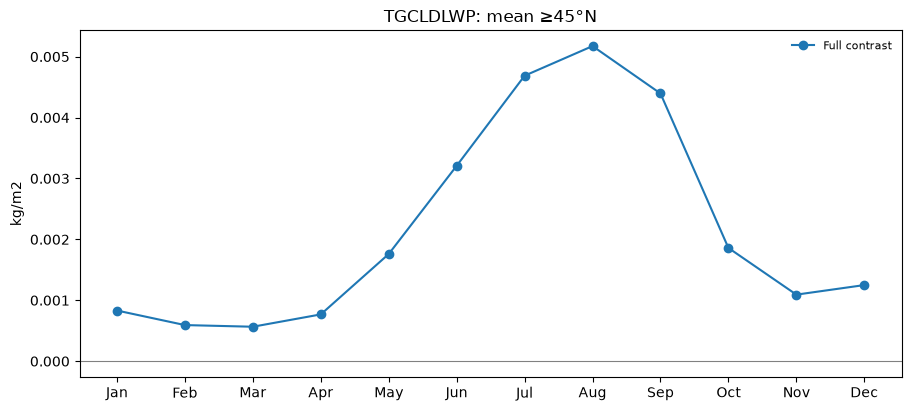

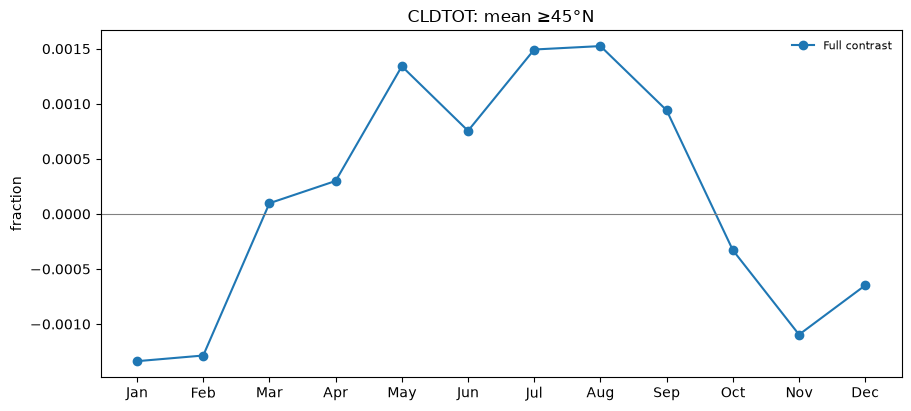

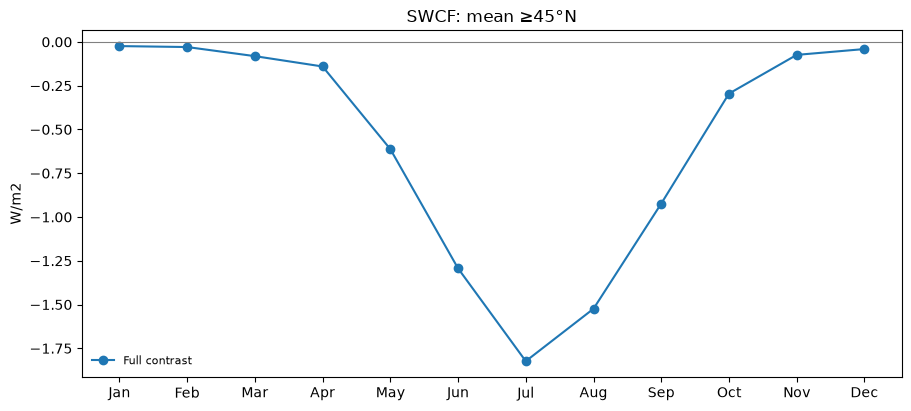

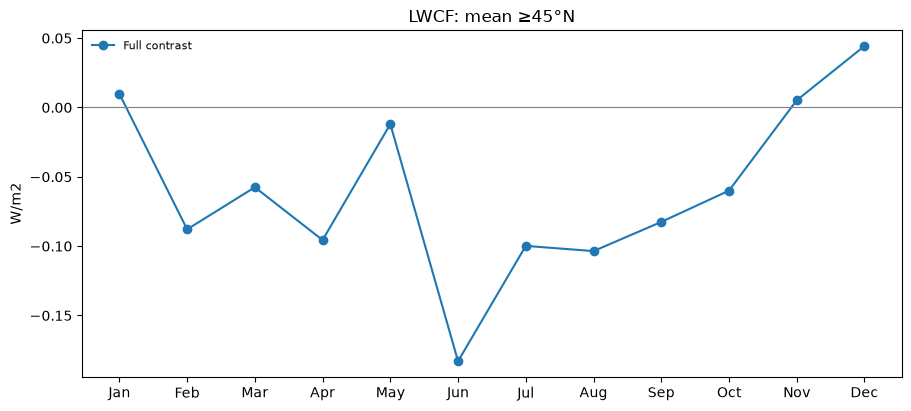

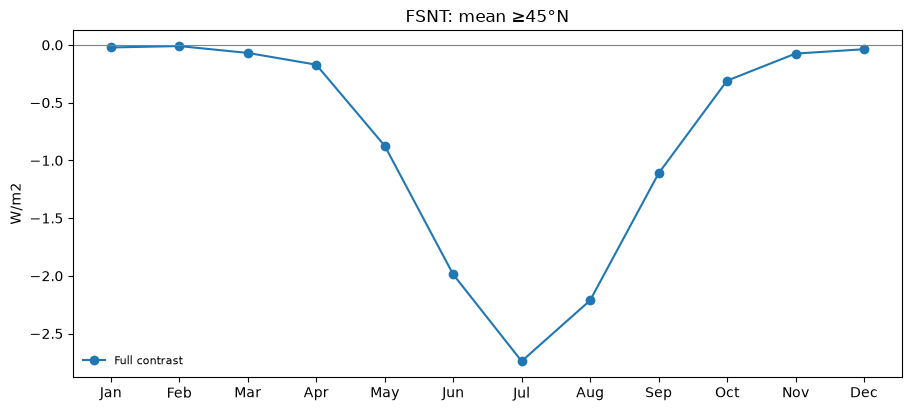

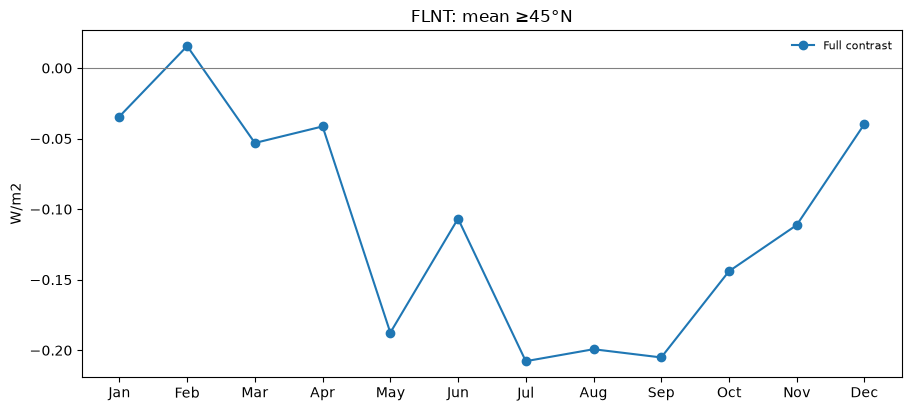

,diagnostic,contrast,mean_change,units
0,cb_ISOP,Full contrast,1.241231e-07,kg/m2
1,cb_MTERP,Full contrast,1.049374e-07,kg/m2
2,cb_SOA_LV,Full contrast,5.874999e-10,kg/m2
3,cb_SOA_SV,Full contrast,4.282462e-10,kg/m2
4,AOD_VIS,Full contrast,5.389764e-03,unitless
5,CDNUMC,Full contrast,1.613435e+09,1/m2
6,ACTREL,Full contrast,-5.740351e-02,Micron
7,TGCLDLWP,Full contrast,2.192898e-03,kg/m2
8,CLDTOT,Full contrast,1.572501e-04,fraction
9,SWCF,Full contrast,-5.758917e-01,W/m2


In [19]:
atmosphere = {}
for label, spec in ATM_INPUTS.items():
    print(f"Loading {label}")
    atmosphere[label] = {case: load_monthly_field(path, spec["variable"]) for case, path in spec["paths"].items()}

response_rows = []
for label, datasets in atmosphere.items():
    if "LCC_FUT" not in datasets:
        raise ValueError(f"{label}: LCC_FUT required.")
    responses = {}
    if "LCC_FUT_fBVOCctrlPD_IM" in datasets:
        responses["Full contrast"] = paired_difference(datasets["LCC_FUT"], datasets["LCC_FUT_fBVOCctrlPD_IM"])
    if "LCC_FUT_fBVOCctrlFUT" in datasets:
        responses["LCC emissions effect"] = paired_difference(datasets["LCC_FUT"], datasets["LCC_FUT_fBVOCctrlFUT"])
    if {"LCC_FUT_fBVOCctrlPD_IM", "LCC_FUT_fBVOCctrlFUT"}.issubset(datasets):
        responses["PD→FUT prescribed emissions effect"] = paired_difference(
            datasets["LCC_FUT_fBVOCctrlFUT"], datasets["LCC_FUT_fBVOCctrlPD_IM"])
        xr.testing.assert_allclose(responses["LCC emissions effect"] +
                                   responses["PD→FUT prescribed emissions effect"], responses["Full contrast"])
    if not responses:
        print(f"{label}: no paired fixed-reference case configured.")
        continue
    fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
    for name, field in responses.items():
        series = regional_series(field, north)
        cycle = (series * seconds).groupby("month").sum() / seconds.groupby("month").sum()
        ax.plot(cycle.month, cycle, "o-", label=name)
        response_rows.append({"diagnostic": label, "contrast": name,
                              "mean_change": float((series * seconds).sum() / seconds.sum()),
                              "units": datasets["LCC_FUT"].attrs["units"]})
    ax.axhline(0, color="0.5", linewidth=.8)
    ax.set(title=f"{label}: mean ≥{MIN_LAT}°N", ylabel=datasets["LCC_FUT"].attrs["units"],
           xticks=range(1, 13), xticklabels=list(calendar.month_abbr)[1:])
    ax.legend(frameon=False, fontsize=8)
    safe_label = "".join(c if c.isalnum() else "_" for c in label)
    fig.savefig(OUT / f"atmospheric_response_{safe_label}.png", dpi=200)
    plt.show()
if response_rows:
    response_summary = pd.DataFrame(response_rows)
    display(response_summary)
    response_summary.to_csv(OUT / "atmospheric_response_decomposition.csv", index=False)
else:
    print("Atmospheric comparisons skipped: configure ATM_INPUTS.")


## Findings from sections 14–17 (2001–2009)

**14. Mechanisms (JJA, LCC_FUT − CTRL_FUT).** Leaf area is lower almost everywhere ≥45°N: TLAI −0.46 (modified), **−0.41 (unmodified)**, −1.3 to −1.4 m² m⁻² (hotspots), and it stays lower all year round. Vegetation is warmer (TV +0.3 to +0.8 K) and receives more sunlight (FSDS +0.2 to +2.4 W m⁻²). Both of those would *raise* emissions, so the emission decrease follows the loss of leaf area.

**Likely cause (inference, not proven):** the LAI loss outside the modified cells, where the plant types did not change, matches the legacy of the FUT land-only spin-up that ran at 284 ppm CO₂ (see `diagnostics/check-CO2-bug-in-land-only/`). If so, most of the negative "Expansion" contribution, and the PD/FUT sign flip in `bvoc_expansion_PD_FUT_interaction.ipynb`, is a spin-up artefact, not an effect of forest expansion. Re-check after the corrected spin-ups.

**15. Plant-type changes in the modified cells** (percentage points of natural vegetation): PFT 12 −7.9, PFT 0 (bare) −3.5, PFT 8 +4.8, PFT 3 +2.8, PFT 2 +2.3.

**16. Fixed emissions.** LCC_FUT_fBVOCctrlPD_IM receives 0.047 % less SFISOP/SFMTERP than CTRL_PD in every region, and the map RMSE is ≤0.0004 mg m⁻² d⁻¹. The prescription reproduces its source.

**17. Full contrast LCC_FUT − LCC_FUT_fBVOCctrlPD_IM** (≥45°N annual mean): AOD_VIS +0.0054, CDNUMC +1.6×10⁹ m⁻², ACTREL −0.057 µm, TGCLDLWP +2.2 g m⁻², SWCF −0.58 W m⁻², LWCF −0.06 W m⁻², FSNT −0.81 W m⁻², FLNT −0.11 W m⁻². This contrast mixes the future background, the LCC effect on emissions, and the possible spin-up artefact, so it is **not** a forest-expansion BVOC effect. The clean contrast needs `LCC_FUT_fBVOCctrlFUT`.

Outputs: `mechanism_JJA_changes.csv`, `PFT_changes_modified_cells.csv`, `fixed_emissions_vs_source.csv`, `atmospheric_response_decomposition.csv` and figures in `bvoc_emissions_decomposition_outputs/`.

## Recommended reading order
1. Regional totals: locate the negative expansion contribution.
2. Seasonal and cancellation panels: identify active months and opposing spatial changes.
3. Ranked cells and narrow-scale maps: identify the locations to investigate.
4. PFT and environmental diagnostics: evaluate candidate mechanisms without treating correlation as proof.
5. Fixed-emission checks: verify the intended reference contrasts.
6. Atmospheric comparisons: diagnose the aerosol/cloud/radiative responses independently of the sign of the emissions total.

All outputs go to the single configured OUT directory. Only `LCC_FUT_fBVOCctrlFUT` is still unset (run not done). This notebook is standalone.